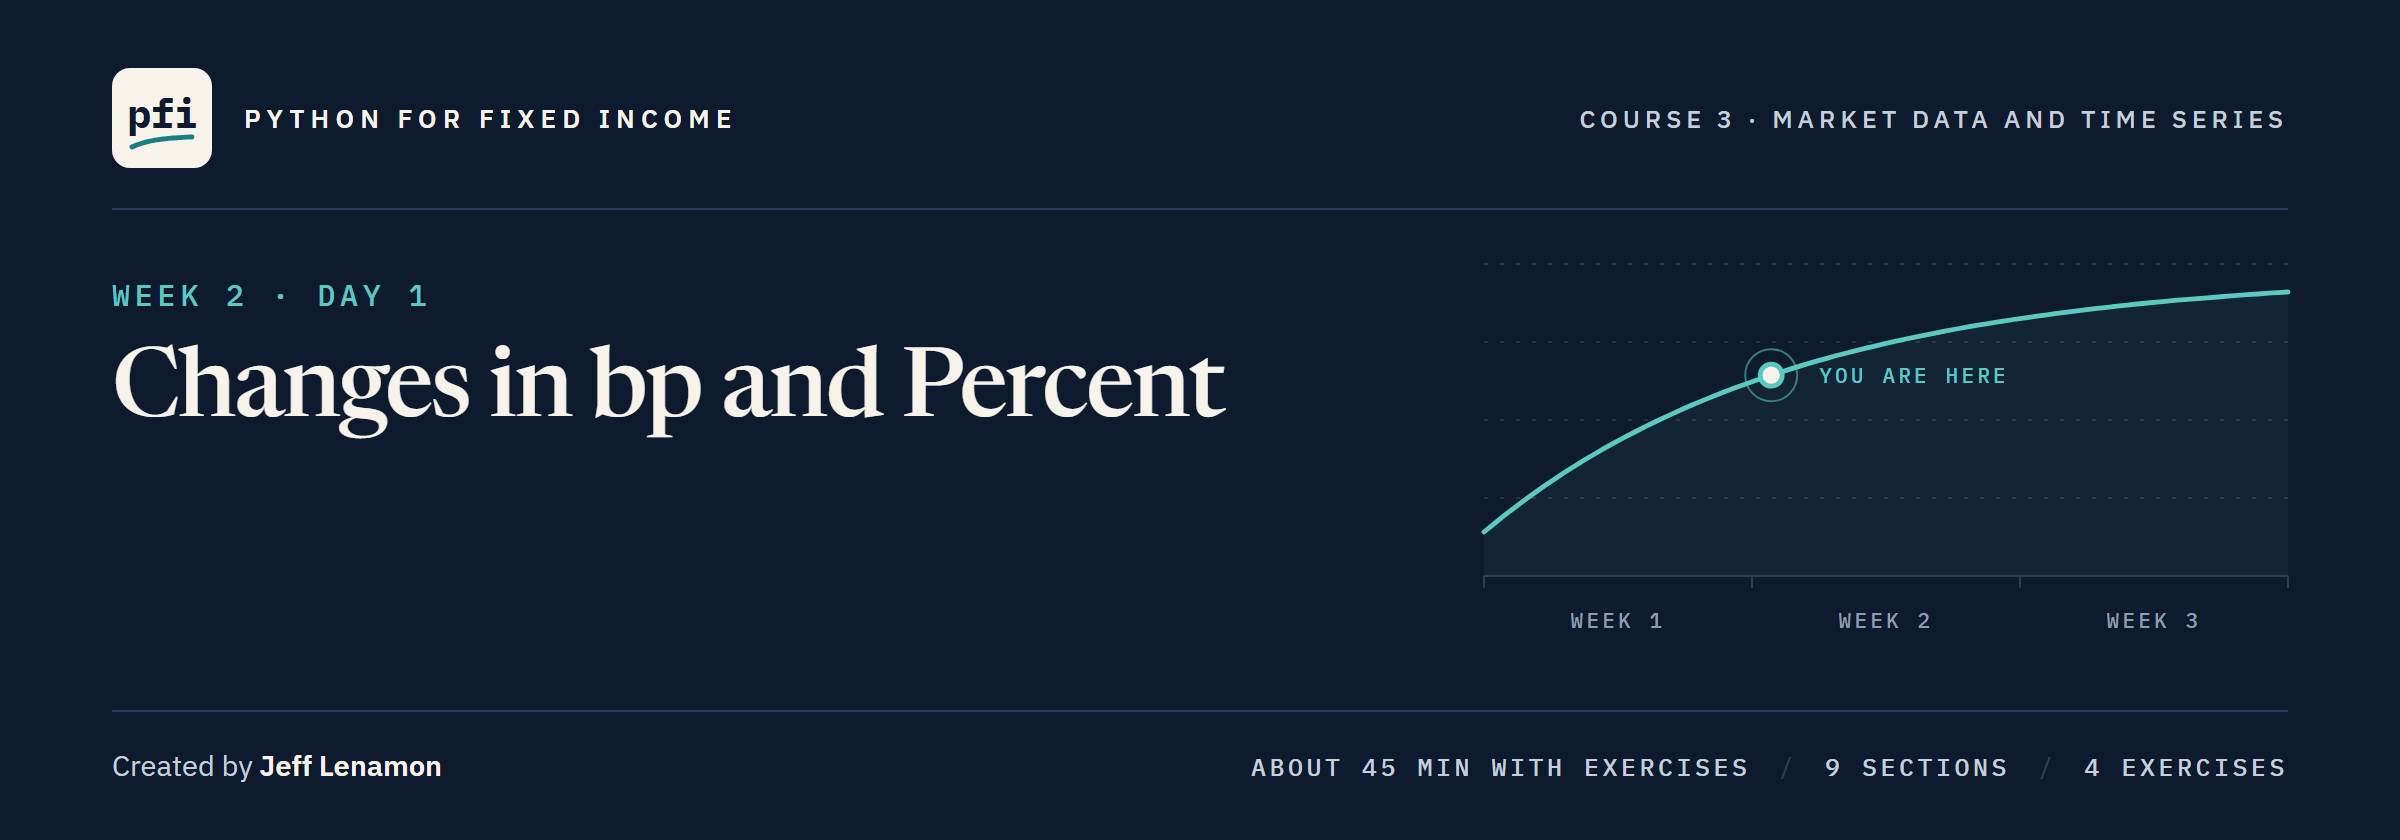

# Changes in bp and Percent

Week 2, Day 1. How far each series moved, in its own unit: yields and spreads in bp, prices in percent, over a day, a week, a month and the year, tied to Excel.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day1/06_changes_in_bp_and_percent.ipynb)

### The Desk Lead's Note

> Week 2 measures the dataset. The morning note opens with how far each series moved: on the day, over the week, over the month, and since the end of last year. Give me that for the 2, 5, 10 and 30 Yr and the two synthetic spreads as of 2 October, each in its right unit and tied to Excel. A market holiday must never show up as a zero move. Then show me what September's move in the 5 Yr did to a bond's price. Last, which days of 2026 moved the 10 Yr most? Describe; no views.

The two files are notebook 05's: Treasury yields in percent, and synthetic spreads in bp, invented for this course, not ICE, Moody's, or any index.
Today reads only these files, so there is no key cell and no live cell.

### Today's Work Folder

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 05 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(6)

Work folder pfi_course3_06_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 05 left it, 5 commits, tagged week1


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................                                                     [100%]
20 passed in 0.50s



### Imports and the Two Files

In [3]:
import importlib
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import bondmath
import marketdata as md

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

In [4]:
# yields in percent and the synthetic spreads in bp, every digit as written
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
ten = treasury['10 Yr']
ig = spreads['ig_spread_bp']

**Yields arrive in percent and spreads in bp: the unit of a move starts from the unit of the series.**

## Your Route Through Day 1

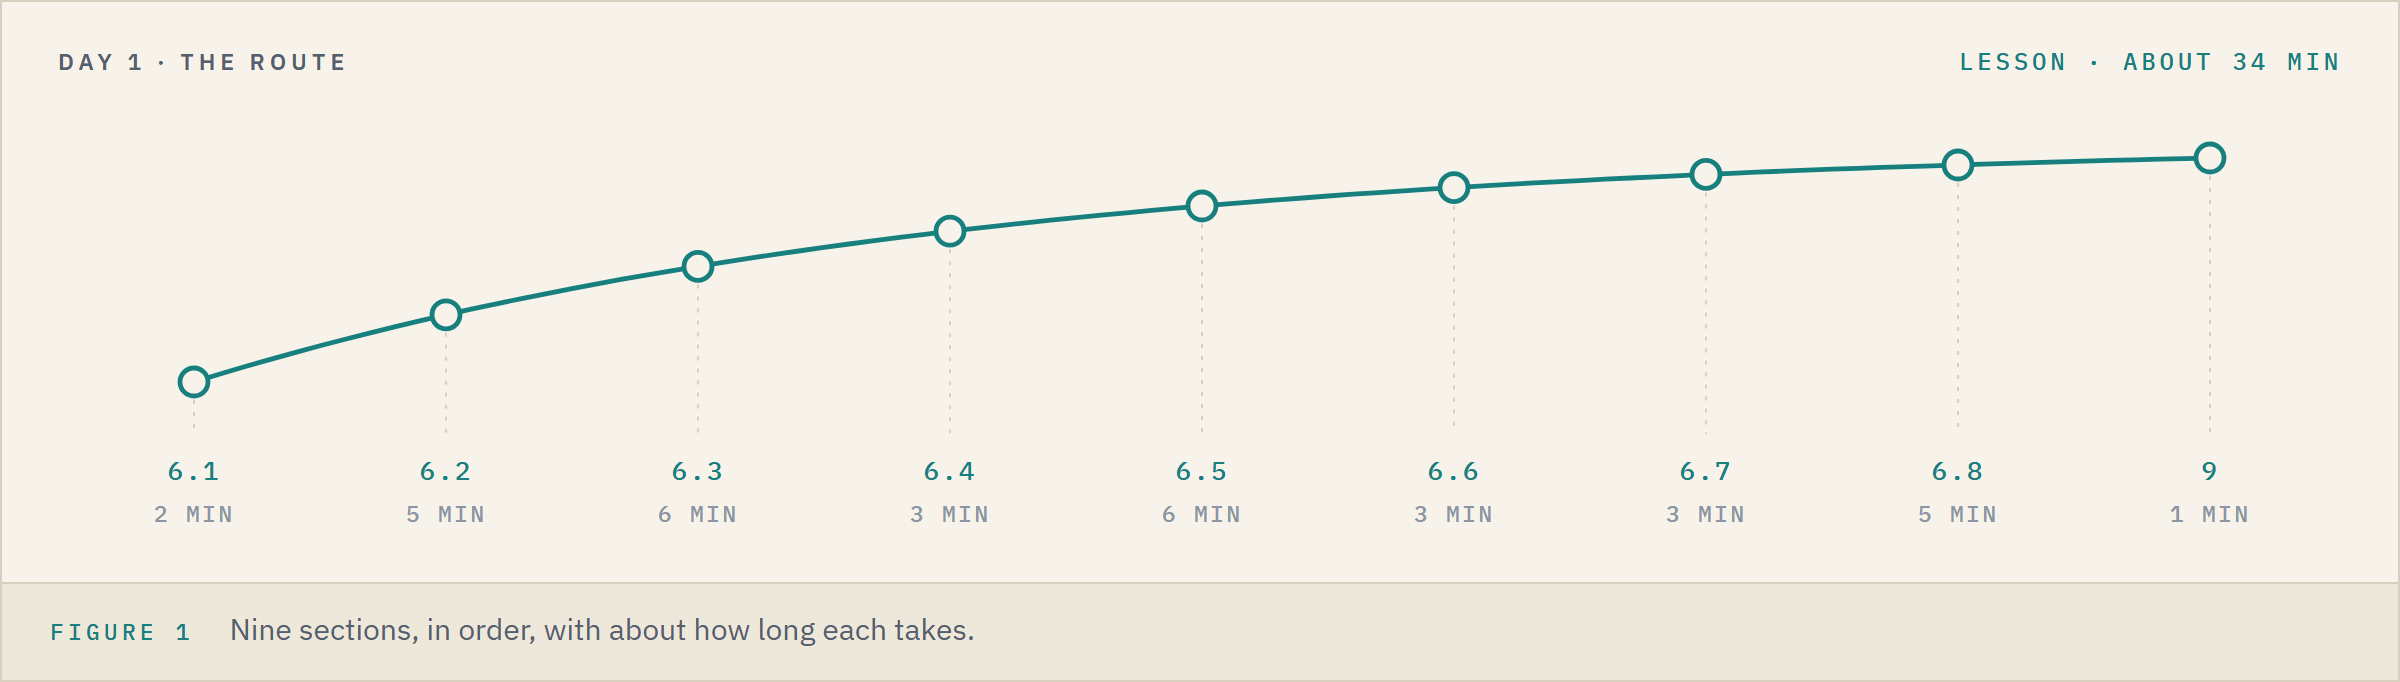

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">6.1</td><td align="left">Yields and Spreads Change in bp, Prices in Percent</td><td align="left">2 min</td></tr>
<tr><td align="left">6.2</td><td align="left"><code>change_bp</code>: Rows Back, Not Days Back</td><td align="left">5 min</td></tr>
<tr><td align="left">6.3</td><td align="left">The Wrong Unit, Blank Rows, and <code>return_pct</code></td><td align="left">6 min</td></tr>
<tr><td align="left">6.4</td><td align="left">Why a Percent Change of a Yield Misleads</td><td align="left">3 min</td></tr>
<tr><td align="left">6.5</td><td align="left">Changes Since a Date: <code>change_since_bp</code></td><td align="left">6 min</td></tr>
<tr><td align="left">6.6</td><td align="left">Which Notebook Wrote Each Line: <code>git blame</code></td><td align="left">3 min</td></tr>
<tr><td align="left">6.7</td><td align="left">A Price Return From Your <code>bondmath</code></td><td align="left">3 min</td></tr>
<tr><td align="left">6.8</td><td align="left">The Largest Daily Moves of 2026</td><td align="left">5 min</td></tr>
<tr><td align="left">9</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 34 minutes for the lesson, then about 12 for the four exercises.

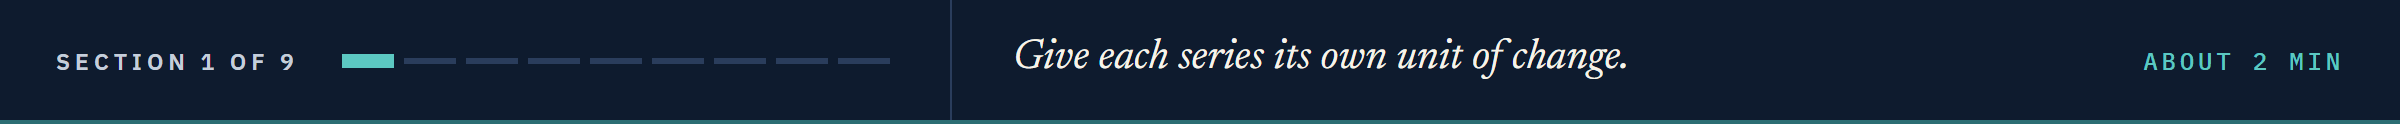

## 6.1 Yields and Spreads Change in bp, Prices in Percent

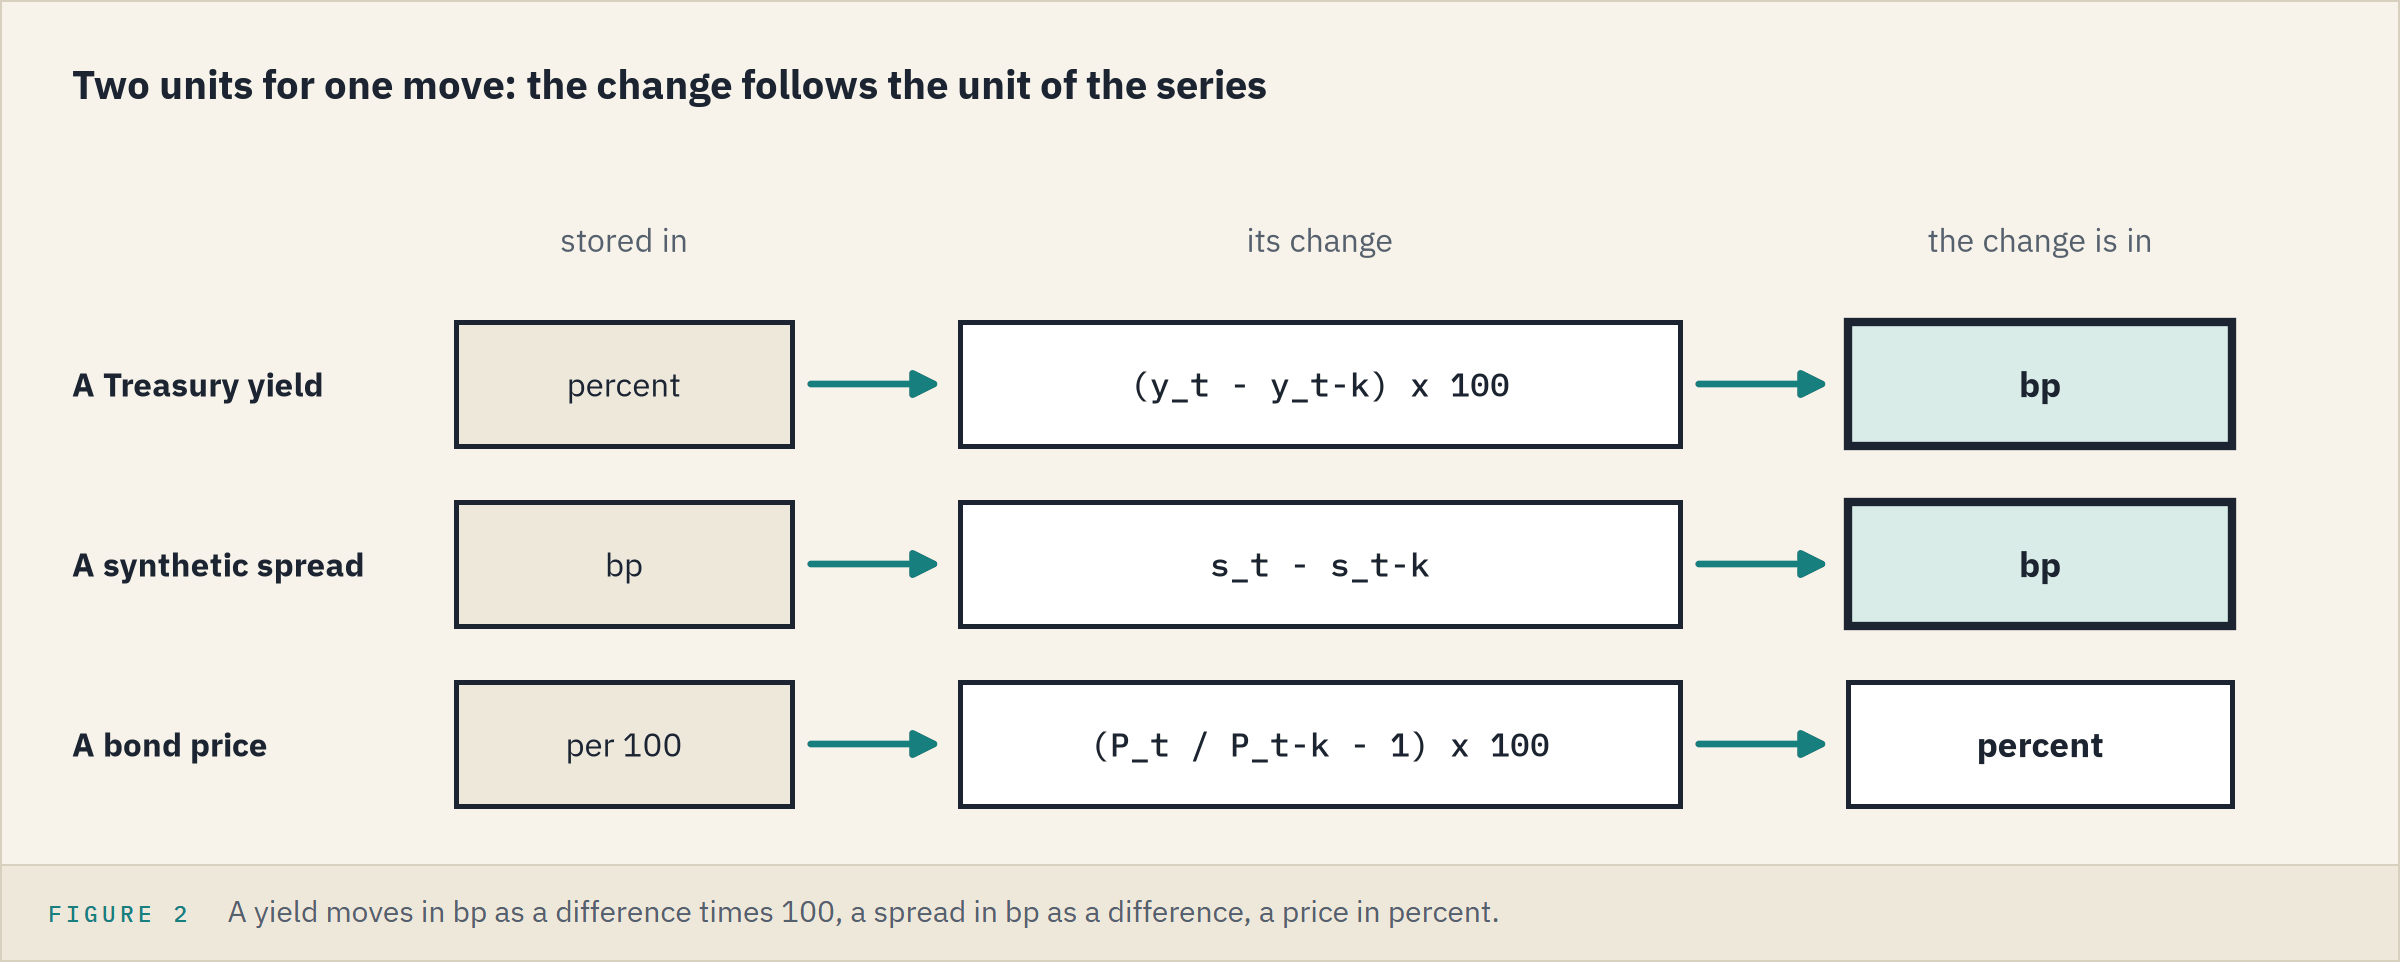

A yield and a spread are rates, so a move is a difference of rates, in bp.
A price is money, so a move is a share of where it started.

### The Last Day, by Hand

Q. How far did the 10 Yr and the synthetic IG spread move on 2 October?

In [5]:
# a yield is in percent: the difference times 100 is in bp
ten_move_bp = (ten.iloc[-1] - ten.iloc[-2]) * 100
# a spread is already in bp: the difference is the move
ig_move_bp = ig.iloc[-1] - ig.iloc[-2]
print(f'10 Yr: {ten.iloc[-2]:.2f} to {ten.iloc[-1]:.2f} percent, {ten_move_bp:+.1f} bp')
print(f'IG spread (synthetic): {ig.iloc[-2]:.1f} to {ig.iloc[-1]:.1f} bp, {ig_move_bp:+.1f} bp')

10 Yr: 5.24 to 5.28 percent, +4.0 bp
IG spread (synthetic): 98.0 to 97.0 bp, -1.0 bp


`+` in a format code always shows the sign, as in Course 2's Price-Yield notebook.
Write k for the number of rows back: a change is always from an earlier row, never from a day with no row.

**A yield's move is a difference times 100, a spread's a plain difference, both in bp. Next, one function for both.**

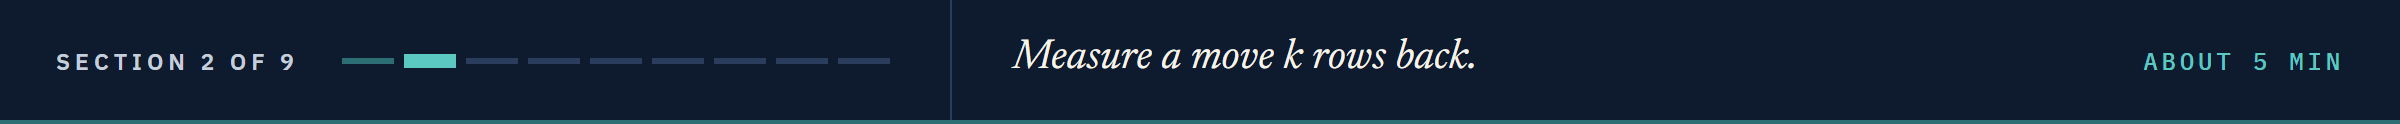

## 6.2 `change_bp`: Rows Back, Not Days Back

The hand sum becomes a function.
It needs one fact beyond the series: is it in percent?

### Append It, Docstring First

Q. Read the docstring, then append `change_bp`.

In [6]:
%%writefile -a marketdata.py


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference

Appending to marketdata.py


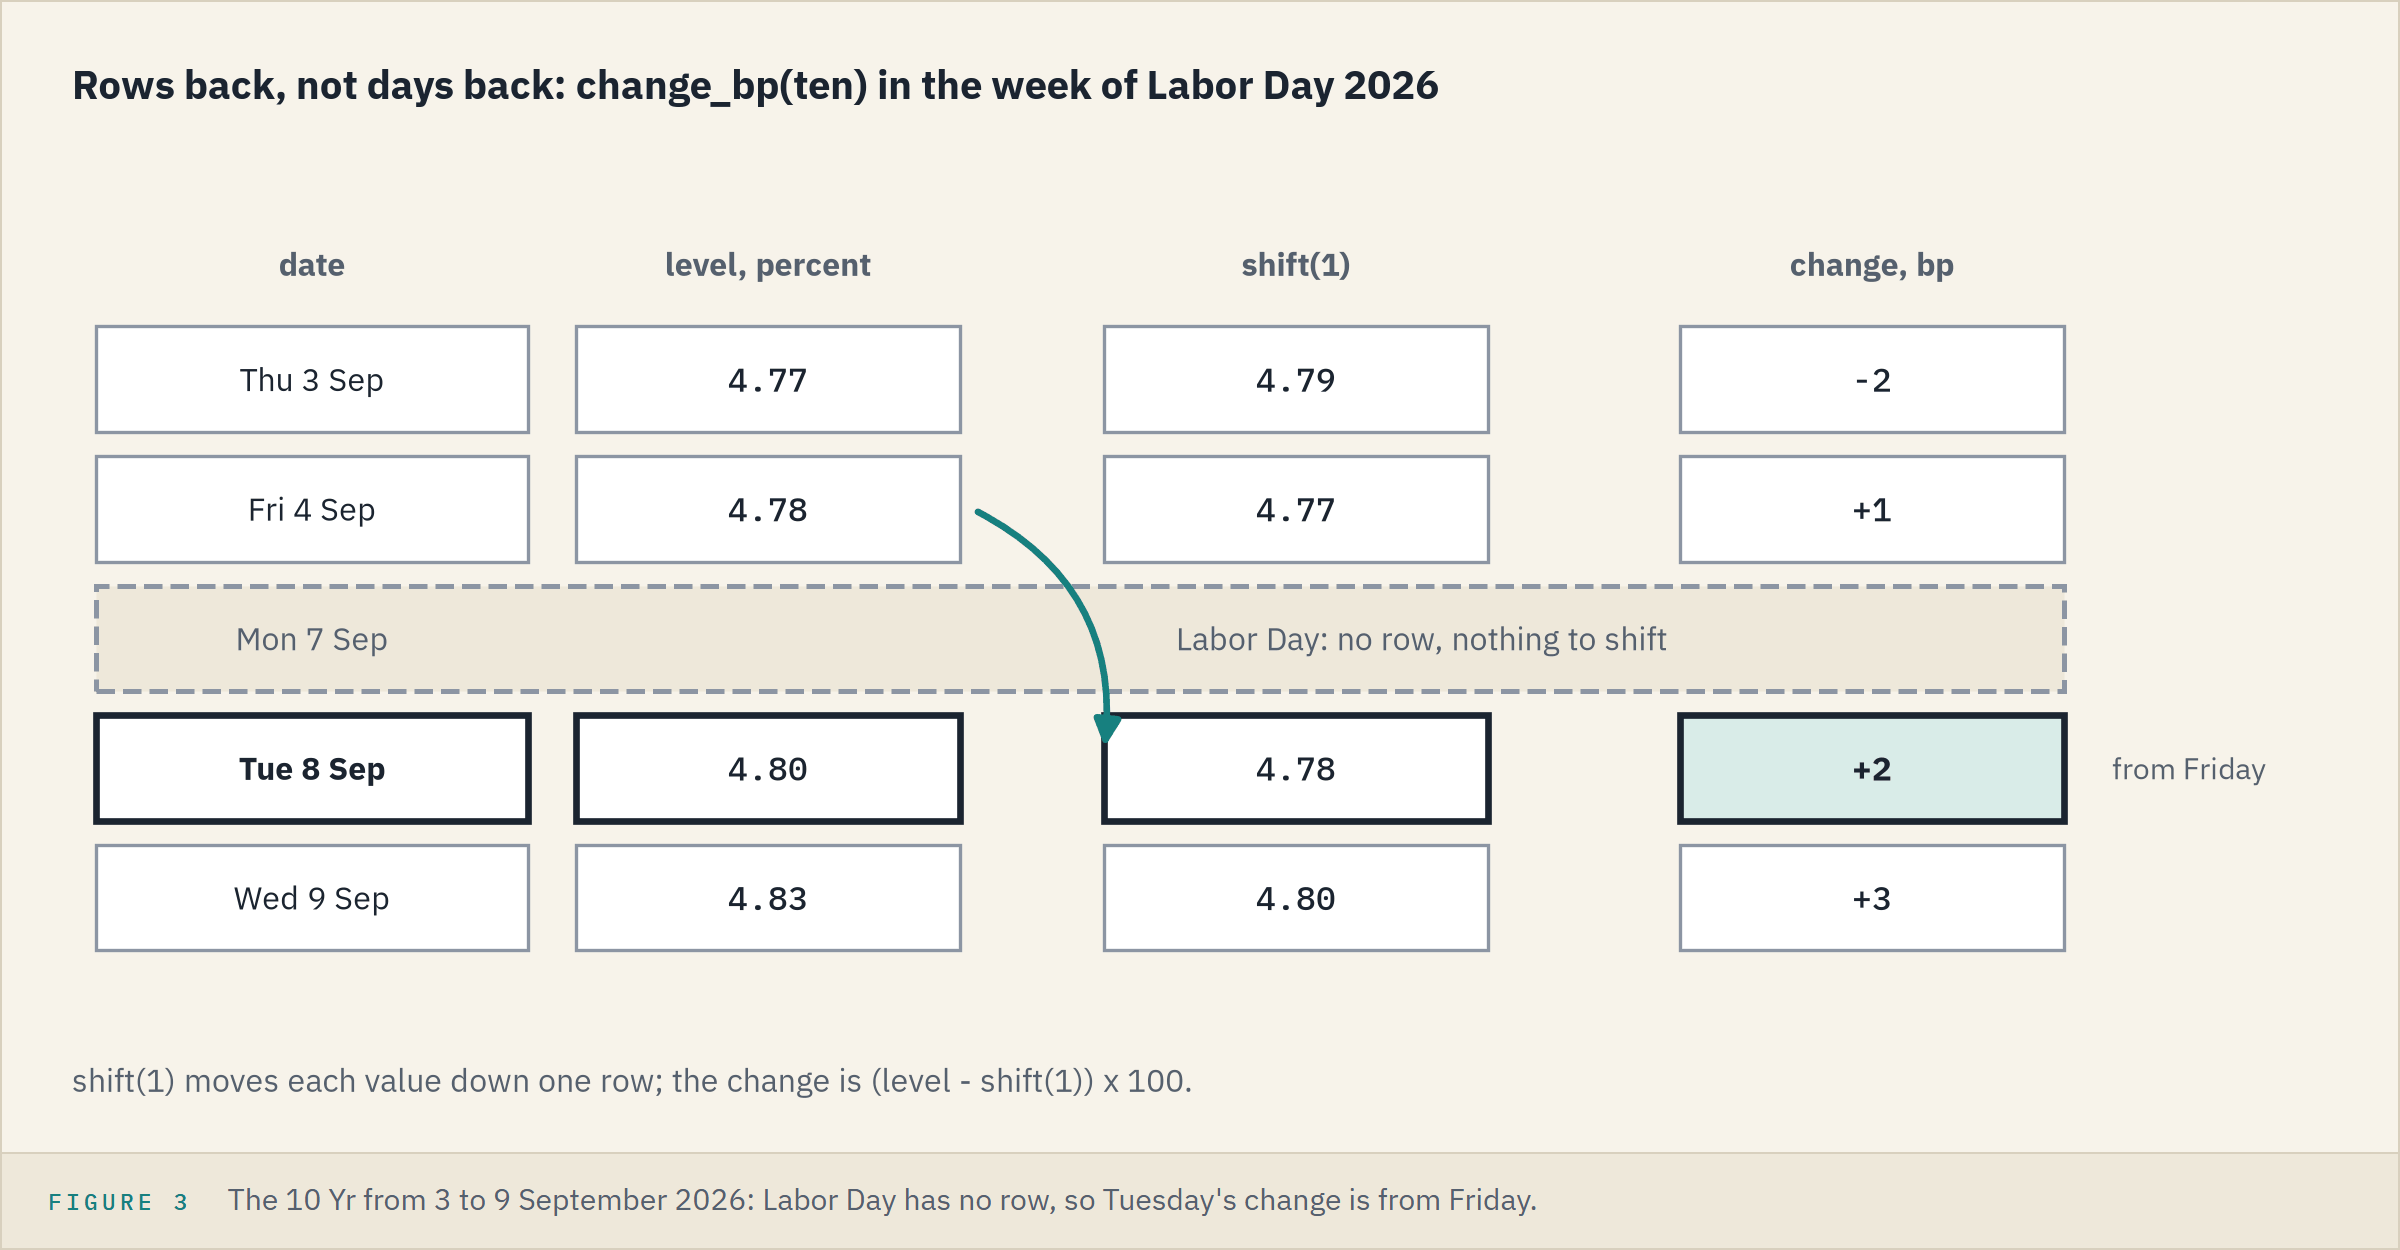

`series.shift(periods)` is notebook 03's `.shift()`, moved `periods` rows; `_check_series` is notebook 04's.

### One and Five Observations

Q. The 10 Yr's level with its 1-row and 5-row changes, for the last six days.

In [7]:
importlib.reload(md)
# the level in percent, then the change from one row back and from five rows back, in bp
moves = pd.DataFrame({'level_pct': ten, 'chg_1_bp': md.change_bp(ten),
                      'chg_5_bp': md.change_bp(ten, periods=5)})
moves.tail(6).round(2)

,level_pct,chg_1_bp,chg_5_bp
date,,,
2026-09-25,5.17,-1.0,16.0
2026-09-28,5.24,7.0,28.0
2026-09-29,5.26,2.0,30.0
2026-09-30,5.29,3.0,18.0
2026-10-01,5.24,-5.0,6.0
2026-10-02,5.28,4.0,11.0


### The Week of Labor Day

Q. Monday 7 September has no row. What does Tuesday's change compare with?

In [8]:
# Thursday 3 to Wednesday 9 September
moves.loc['2026-09-03':'2026-09-09'].round(2)

,level_pct,chg_1_bp,chg_5_bp
date,,,
2026-09-03,4.77,-2.0,10.0
2026-09-04,4.78,1.0,5.0
2026-09-08,4.80,2.0,5.0
2026-09-09,4.83,3.0,4.0


Tuesday is +2 bp from Friday's 4.78: a holiday is skipped, never a zero change.

### Predict 1: Five Rows Back From Tuesday

**Predict 1**

Q. `chg_5_bp` on Tuesday 2026-09-08 goes back five rows. From which date?

A) Tuesday 2026-09-01
B) Monday 2026-08-31
C) Thursday 2026-09-03

### Count Them

In [9]:
# get_loc gives a date's row number in the index; five rows up is five market days back
tuesday = ten.index.get_loc(pd.Timestamp('2026-09-08'))
# :%Y-%m-%d after a date in braces writes it year-month-day, Course 1's EDA format codes
print(f'Five rows back from 2026-09-08: {ten.index[tuesday - 5]:%Y-%m-%d}')

Five rows back from 2026-09-08: 2026-08-31


B: eight calendar days back for five rows, because the week had a holiday.

### Two Weeks of September, Drawn

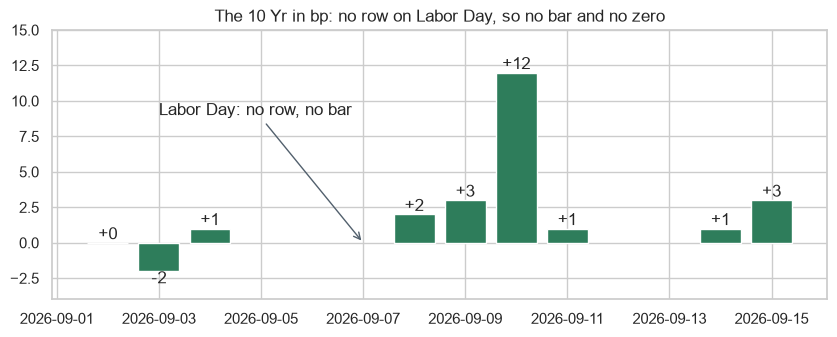

In [10]:
# one bar per market day, each labelled; Labor Day has no row, so no bar
early_september = moves.loc['2026-09-02':'2026-09-15', 'chg_1_bp']
fig, ax = plt.subplots(figsize=(10, 3.5))
bars = ax.bar(early_september.index, early_september.values)
ax.bar_label(bars, fmt='{:+.0f}')
ax.annotate('Labor Day: no row, no bar', xy=(pd.Timestamp('2026-09-07'), 0),
            xytext=(pd.Timestamp('2026-09-03'), 9),
            arrowprops={'arrowstyle': '->', 'color': '#52606D'})
ax.set_ylim(-4, 15)
ax.set_title('The 10 Yr in bp: no row on Labor Day, so no bar and no zero')
plt.show()

Wednesday 2 September's +0 is a real row that did not move; Labor Day is no row at all.

### Every Row Against Excel

Q. Does `change_bp` equal Excel's daily change on every row of 2026?

In [11]:
# Excel's answers: one row per 2026 market date, every value computed by Excel
reference = pd.read_csv('course3_excel_reference.csv', parse_dates=['date'], index_col='date',
                        float_precision='round_trip')
gap = (md.change_bp(ten).loc[reference.index] - reference['chg_10y_bp']).abs().max()
print(f'{len(reference)} rows of 2026, largest gap {gap:.1e} bp')

190 rows of 2026, largest gap 0.0e+00 bp


**Excel side by side.** Dates in A, the 10 Yr in B, from 2025-01-02 in row 2.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Daily change in bp, C3 filled down</td><td align="left"><code>md.change_bp(ten)</code></td><td align="left"><code>=(B3-B2)*100</code></td><td align="left">Equal on all 190 rows of 2026</td></tr>
</table>
<br clear="left">

**`change_bp` counts rows, so a holiday is skipped, never a zero, and it equals Excel on every row of 2026. Next, the inputs it cannot fix by itself.**

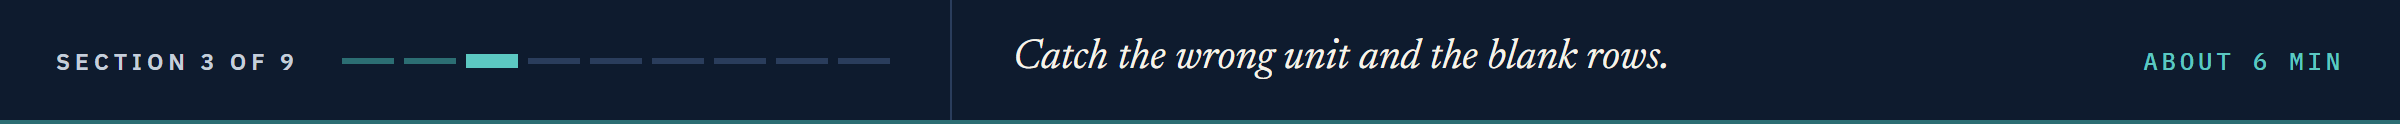

## 6.3 The Wrong Unit, Blank Rows, and `return_pct`

`change_bp` is right on the 10 Yr.
Two inputs can still go wrong, and a price needs a function of its own.

### A Spread Read as a Yield

Q. What if the spread's unit is left at the default?

In [12]:
# a spread is already in bp, so percent_units=False; the default reads it as a yield in percent
ig_bp = md.change_bp(ig, percent_units=False)
ig_as_yield = md.change_bp(ig)
print(f'Last day: {ig_bp.iloc[-1]:+.1f} bp, or {ig_as_yield.iloc[-1]:+.1f} read as a yield')

Last day: -1.0 bp, or -100.0 read as a yield


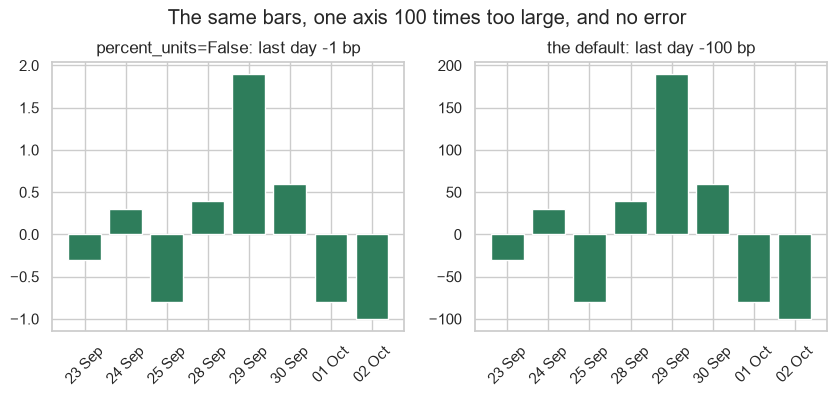

In [13]:
# the last eight changes both ways, labelled by day and month
last_eight = pd.DataFrame({'percent_units=False': ig_bp, 'the default': ig_as_yield}).tail(8)
days = [f'{day:%d %b}' for day in last_eight.index]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, column in zip(axes, last_eight.columns):
    ax.bar(days, last_eight[column])
    ax.set_title(f'{column}: last day {last_eight[column].iloc[-1]:+.0f} bp')
    ax.tick_params(axis='x', rotation=45)
fig.suptitle('The same bars, one axis 100 times too large, and no error', y=1.03)
plt.show()

**Excel side by side.** The synthetic IG spread in D, the last row 440.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The spread's last change</td><td align="left"><code>md.change_bp(ig, percent_units=False)</code></td><td align="left"><code>=D440-D439</code></td><td align="left">-1</td></tr>
<tr><td align="left">The same, read as a yield</td><td align="left"><code>md.change_bp(ig)</code></td><td align="left"><code>=(D440-D439)*100</code></td><td align="left">-100</td></tr>
</table>
<br clear="left">

> STORY: Course 1 told how NASA lost the Mars Climate Orbiter in 1999. Thruster data was supplied in English units where the trajectory models expected metric, and the spacecraft arrived about 170 kilometers lower than planned. Source: Mars Climate Orbiter Mishap Investigation Board, Phase I Report, November 10, 1999, pages 6 and 7. https://llis.nasa.gov/llis_lib/pdf/1009464main1_0641-mr.pdf

### A Tenor With Empty Rows

Q. The 4 Mo starts in October 2022. Can `change_bp` take it as it is?

In [14]:
# the 4 Mo as it stands, blank rows and all
md.change_bp(treasury['4 Mo'])

ValueError: series has 1951 missing values; drop them first with .dropna()

In [15]:
# drop the blank rows first, as the message says
four_month = treasury['4 Mo'].dropna()
print(f'{len(four_month):,} rows from {four_month.index[0]:%Y-%m-%d}, '
      f'last change {md.change_bp(four_month).iloc[-1]:+.1f} bp')

989 rows from 2022-10-19, last change +0.0 bp


Drop, never fill, before a change: a filled blank is a zero move the market never made.

### The Price's Function: `return_pct`

In [16]:
%%writefile -a marketdata.py


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100

Appending to marketdata.py


### Up 1 Percent, Down 1 Percent

In [17]:
importlib.reload(md)
hand_prices = pd.Series([100.0, 101.0, 99.99],
                        index=pd.to_datetime(['2026-09-28', '2026-09-29', '2026-09-30']))
# .tolist() gives the values as a plain list
print(md.return_pct(hand_prices).round(6).tolist())

[nan, 1.0, -1.0]


Up 1 percent, down 1 percent, and the price is 99.99, not back at 100: each return is a share of its own start.

### Three Tests

In [18]:
%%writefile -a test_marketdata.py


def test_change_bp_hand_series():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    yields = pd.Series([4.00, 4.10, 4.05], index=dates)
    changes = md.change_bp(yields)
    # 4.00 to 4.10 is 10 bp; the Tuesday after Labor Day is a change from Friday
    assert math.isnan(changes.iloc[0])
    assert changes.iloc[1] == pytest.approx(10.0, abs=1e-9)
    assert changes.loc["2026-09-08"] == pytest.approx(-5.0, abs=1e-9)
    assert md.change_bp(yields, periods=2).iloc[2] == pytest.approx(5.0, abs=1e-9)


def test_change_bp_spread_units():
    spreads = pd.Series([98.8, 101.3], index=pd.to_datetime(["2026-09-29", "2026-09-30"]))
    # a spread is already in bp, so nothing is multiplied
    assert md.change_bp(spreads, percent_units=False).iloc[1] == pytest.approx(2.5, abs=1e-9)


def test_return_pct_hand_series():
    prices = pd.Series([100.0, 101.0, 99.99], index=pd.to_datetime(["2026-09-28", "2026-09-29", "2026-09-30"]))
    returns = md.return_pct(prices)
    assert returns.iloc[1] == pytest.approx(1.0, abs=1e-12)
    assert returns.iloc[2] == pytest.approx(-1.0, abs=1e-12)

Appending to test_marketdata.py


`math.isnan` is notebook 02's: the first change has nothing before it.

### Run pytest

In [19]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................                                                  [100%]
23 passed in 0.50s



**Pass `percent_units=False` for a spread, drop blank rows first, and use `return_pct` for a price. Now the trap the unit argument guards against.**

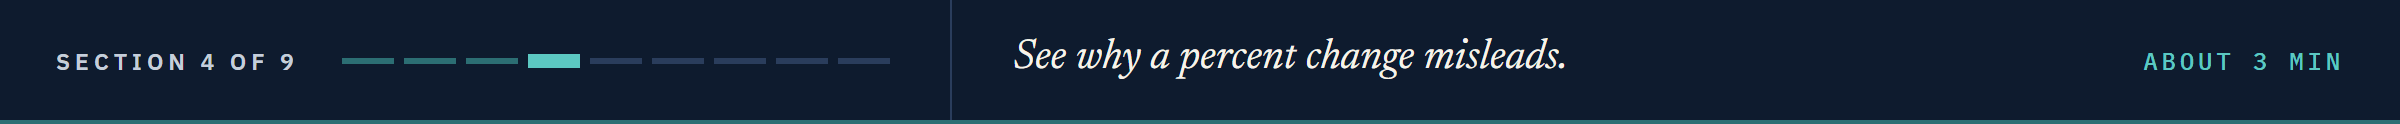

## 6.4 Why a Percent Change of a Yield Misleads

pandas has `pct_change()`, and a spreadsheet has `=B2/B1-1`.
Both are right for a price.

### Predict 2: 4.00 to 4.10

**Predict 2**

Q. A yield moves from 4.00 to 4.10 percent, 10 bp. What does `=B2/B1-1` show in Excel's percent format? Write down a number.

### Both Answers

In [20]:
# 4.00 to 4.10 percent as a two-row series
pair = pd.Series([4.00, 4.10])
print(f'{(pair.iloc[1] - pair.iloc[0]) * 100:.1f} bp')
# pct_change(): each value over the one before, less one
print(f'{pair.pct_change().iloc[1] * 100:.1f} percent of the yield')

10.0 bp
2.5 percent of the yield


**Excel side by side.** 4.00 in B1, 4.10 in B2.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The move in bp</td><td align="left"><code>(4.10 - 4.00) * 100</code></td><td align="left"><code>=(B2-B1)*100</code></td><td align="left">9.999999999999964, shown as 10</td></tr>
<tr><td align="left">The percent of the yield</td><td align="left"><code>pct_change()</code></td><td align="left"><code>=B2/B1-1</code>, percent format</td><td align="left">0.02499999999999991, shown as 2.5%</td></tr>
</table>
<br clear="left">

### The Same 10 bp From Three Levels

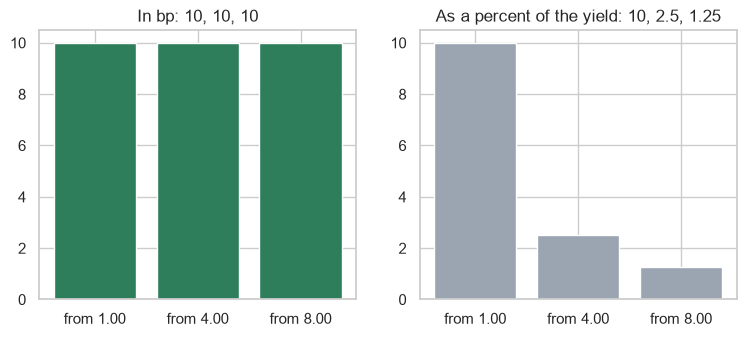

In [21]:
# 10 bp from three starting yields; the bp is the same, the percent is not
levels = pd.Series([1.00, 4.00, 8.00])
same_move = pd.DataFrame({'start_pct': levels, 'move_bp': 10.0,
                          'pct_of_yield': 0.10 / levels * 100})
labels = ['from 1.00', 'from 4.00', 'from 8.00']
fig, (bp_ax, pct_ax) = plt.subplots(1, 2, figsize=(9, 3.5))
bp_ax.bar(labels, same_move['move_bp'])
bp_ax.set_title('In bp: 10, 10, 10')
pct_ax.bar(labels, same_move['pct_of_yield'], color='#9AA5B1')
pct_ax.set_title('As a percent of the yield: 10, 2.5, 1.25')
plt.show()

Course 2's DV01 is per bp, so the bp figure is the one a price answers to.
A relative move of a spread, when someone asks for one, is labelled "relative change, percent".

### Predict 3: The Largest Day Each Way

**Predict 3**

Q. Over the whole file, is the 10 Yr's largest daily percent change on the same day as its largest move in bp?

A) The same day
B) A different day, from a lower starting yield
C) A different day, from a higher starting yield

### Over the Whole File

In [22]:
# every daily change in bp and as a percent of the yield, beside the yield it started from
all_changes = pd.DataFrame({'from_pct': ten.shift(1), 'chg_bp': md.change_bp(ten),
                            'pct_of_yield': ten.pct_change() * 100})
# the largest by size: in bp, then as a percent
biggest = [all_changes['chg_bp'].abs().idxmax(), all_changes['pct_of_yield'].abs().idxmax()]
all_changes.loc[biggest].round(2)

,from_pct,chg_bp,pct_of_yield
date,,,
2022-11-10,4.12,-30.0,-7.28
2020-03-10,0.54,22.0,40.74


B: 22 bp from 0.54 percent is 40.7 percent of the yield, and 30 bp from 4.12 only 7.3.

**The percent of a yield depends on where it started; the bp move does not. Yields and spreads are compared in bp. Next, a move since a date.**

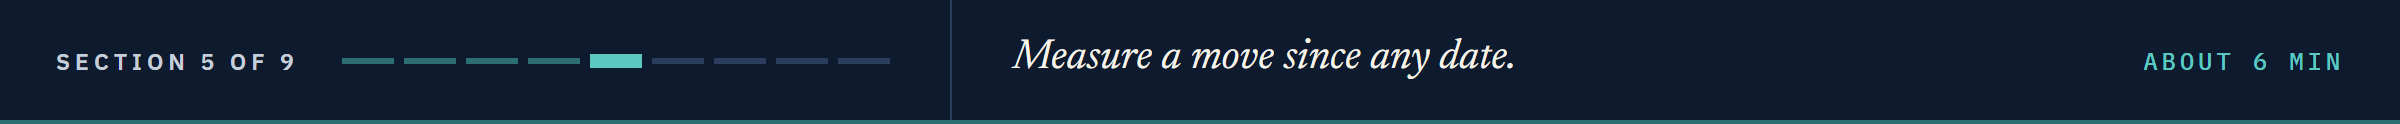

## 6.5 Changes Since a Date: `change_since_bp`

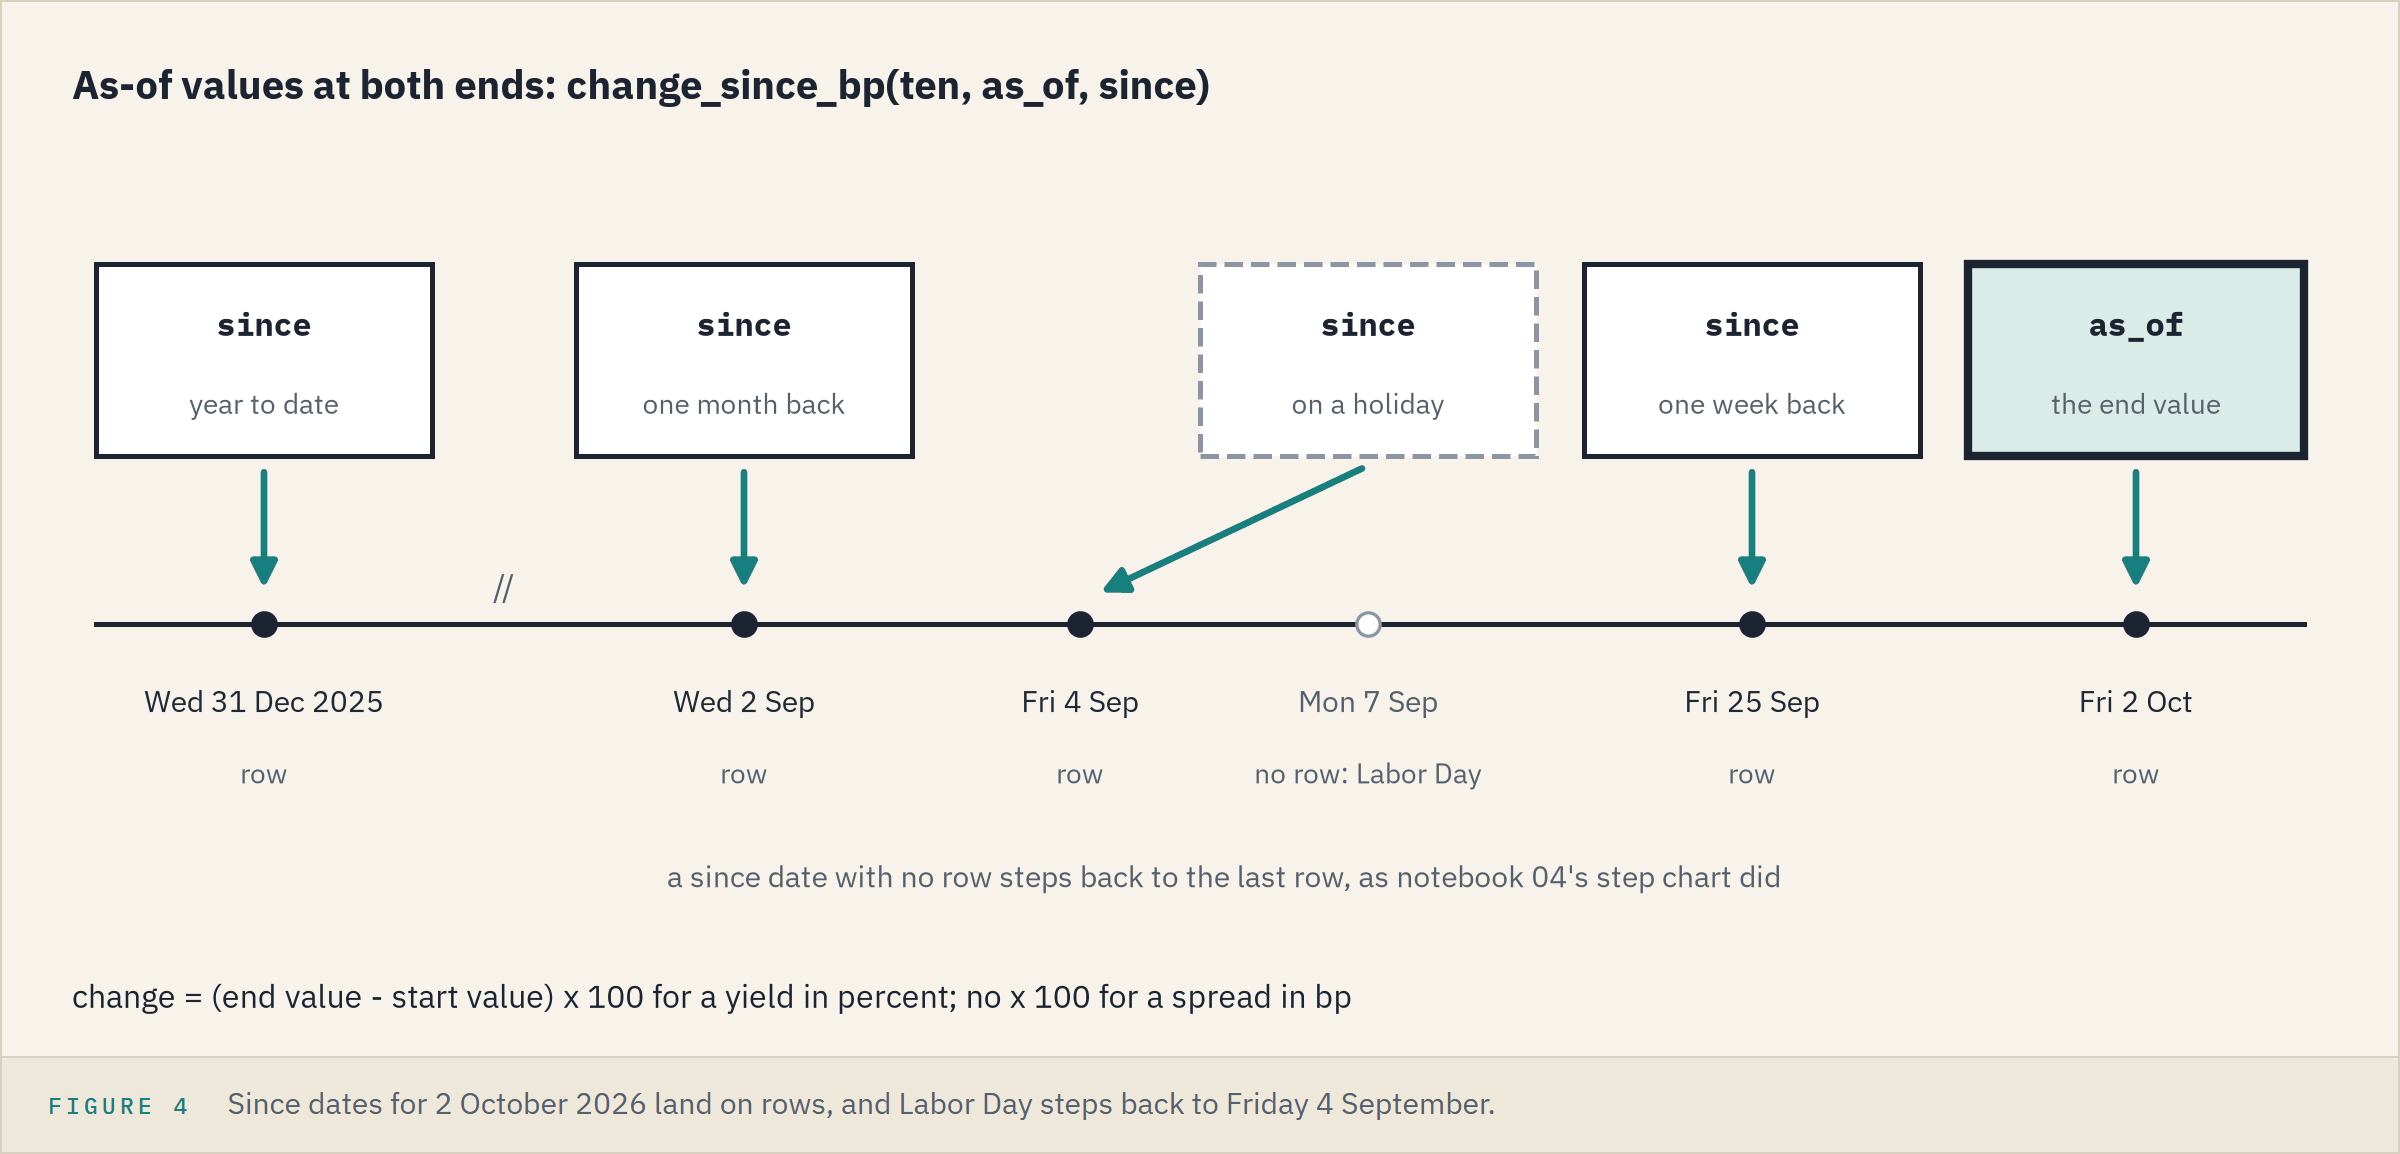

"Up 11 bp on the week" is a change since a date, and that date may have no row.
Each end is notebook 04's as-of value, the step its chart drew.

### Append It, Docstring First

In [23]:
%%writefile -a marketdata.py


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference

Appending to marketdata.py


Two `value_as_of` calls and a subtraction.
A week back is `pd.Timedelta(days=7)`, as in Course 1; a month back is notebook 05's `pd.DateOffset(months=1)`.

### Week, Month, Year to Date

Q. How far has the 10 Yr moved as of 2 October, and from which rows?

In [24]:
importlib.reload(md)
as_of = pd.Timestamp('2026-10-02')
starts = {'week': as_of - pd.Timedelta(days=7), 'month': as_of - pd.DateOffset(months=1),
          'year to date': pd.Timestamp('2025-12-31')}
for label, since in starts.items():
    used, value = md.value_as_of(ten, since)
    print(f'{label:<12} from {used:%Y-%m-%d} at {value:.2f}: '
          f'{md.change_since_bp(ten, as_of, since):+.0f} bp')

week         from 2026-09-25 at 5.17: +11 bp
month        from 2026-09-02 at 4.79: +49 bp
year to date from 2025-12-31 at 4.18: +110 bp


### A Start Date With No Row

In [25]:
# Labor Day has no row, so the start steps back to the market day before it
used, value = md.value_as_of(ten, '2026-09-07')
holiday = md.change_since_bp(ten, '2026-09-30', '2026-09-07')
print(f'Since 2026-09-07: the row of {used:%Y-%m-%d} at {value:.2f}, '
      f'{holiday:+.0f} bp to 2026-09-30')

Since 2026-09-07: the row of 2026-09-04 at 4.78, +51 bp to 2026-09-30


**Excel side by side.** The same sheet, 2026 from row 251.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">One month, filled down</td><td align="left"><code>md.change_since_bp(ten, day, day - pd.DateOffset(months=1))</code></td><td align="left"><code>=(B251-XLOOKUP(EDATE(A251,-1),A:A,B:B,,-1))*100</code></td><td align="left">Equal on all 190 rows</td></tr>
<tr><td align="left">One week, filled down</td><td align="left"><code>md.change_since_bp(ten, day, day - pd.Timedelta(days=7))</code></td><td align="left"><code>=(B251-XLOOKUP(A251-7,A:A,B:B,,-1))*100</code></td><td align="left">Equal on all 190 rows</td></tr>
<tr><td align="left">Year to date</td><td align="left"><code>md.change_since_bp(ten, as_of, '2025-12-31')</code></td><td align="left"><code>=(XLOOKUP(DATE(2026,10,2),A:A,B:B,,-1)-XLOOKUP(DATE(2025,12,31),A:A,B:B,,-1))*100</code></td><td align="left">110.00000000000006</td></tr>
<tr><td align="left">Since Labor Day</td><td align="left"><code>holiday</code></td><td align="left">the same, with <code>DATE(2026,9,30)</code> and <code>DATE(2026,9,7)</code></td><td align="left">50.99999999999998</td></tr>
<tr><td align="left">A month before 31 March</td><td align="left"><code>pd.DateOffset(months=1)</code></td><td align="left"><code>=EDATE(DATE(2026,3,31),-1)</code></td><td align="left">2026-02-28 in both</td></tr>
</table>
<br clear="left">

### The Morning Note's Table

Q. Every series the note names, on the day, the week, the month and the year, all in bp.

In [26]:
# the four tenors and the two synthetic spreads side by side; the day starts from 1 October's row
market = treasury[['2 Yr', '5 Yr', '10 Yr', '30 Yr']].join(spreads)
periods = {'day': pd.Timestamp('2026-10-01')} | starts

In [27]:
# one row of moves per series, each since its start date
rows = {}
for column in market.columns:
    # yields are in percent; the spreads are already in bp
    percent = column.endswith('Yr')
    rows[column] = {label: md.change_since_bp(market[column], as_of, since, percent_units=percent)
                    for label, since in periods.items()}
period_changes = pd.DataFrame(rows).T
# each column's largest move green; highlight_min shades the smallest, as highlight_max the largest
(period_changes.style.format('{:+.1f}')
    .highlight_max(color='#DDEFE5').highlight_min(color='#E6EAED'))

,day,week,month,year to date
2 Yr,+5.0,+2.0,+44.0,+136.0
5 Yr,+5.0,+8.0,+52.0,+133.0
10 Yr,+4.0,+11.0,+49.0,+110.0
30 Yr,+2.0,+14.0,+36.0,+79.0
ig_spread_bp,-1.0,+1.1,+1.9,+8.2
hy_spread_bp,-1.3,+11.2,+0.1,+75.7


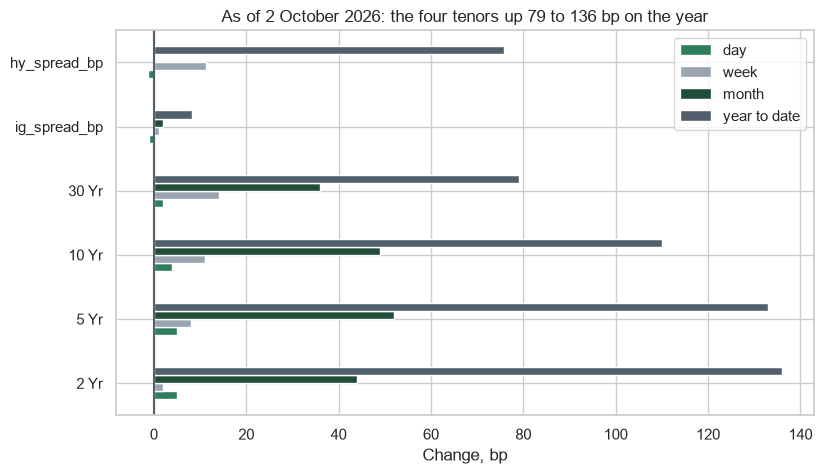

In [28]:
# every move on one axis: all in bp, so they can share it
fig, ax = plt.subplots(figsize=(9, 5))
period_changes.plot.barh(ax=ax)
ax.axvline(0, color='#52606D')
ax.set_title('As of 2 October 2026: the four tenors up 79 to 136 bp on the year')
ax.set_xlabel('Change, bp')
plt.show()

The table describes the file as of 2 October and says nothing of what comes next.

### Two Tests Against Excel

In [29]:
%%writefile -a test_marketdata.py


def read_reference() -> pd.DataFrame:
    """The Excel reference rows in this folder: one per 2026 market date, every value computed by Excel."""
    return pd.read_csv(HERE / "course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                       float_precision="round_trip")


def test_change_since_uses_as_of_values():
    ten = read_treasury()["10 Yr"]
    # since Labor Day 2026-09-07 (no row) means since Friday 2026-09-04
    expected = (ten.loc["2026-09-30"] - ten.loc["2026-09-04"]) * 100
    assert md.change_since_bp(ten, "2026-09-30", "2026-09-07") == pytest.approx(expected, abs=1e-9)
    with pytest.raises(ValueError):
        md.change_since_bp(ten, "2026-09-07", "2026-09-30")


def test_change_bp_matches_excel_reference():
    reference = read_reference()
    ten = read_treasury()["10 Yr"]
    changes = md.change_bp(ten)
    for day, row in reference.iterrows():
        # Excel: =(D_t-D_t-1)*100, filled down
        assert changes.loc[day] == pytest.approx(row["chg_10y_bp"], abs=1e-9), day
        # the one-month as-of change: =(D_t-XLOOKUP(EDATE(A_t,-1),...,-1))*100
        month_back = day - pd.DateOffset(months=1)
        assert md.change_since_bp(ten, day, month_back) == pytest.approx(row["chg1m_10y_bp"], abs=1e-9), day

Appending to test_marketdata.py


`iterrows()` hands over each row in turn: its date, then its values.

### Run pytest

In [30]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................                                                [100%]
25 passed in 0.50s



**Every move in the morning note is in bp, from as-of values at both ends, equal to Excel on every 2026 row. The module is done for the day: commit it.**

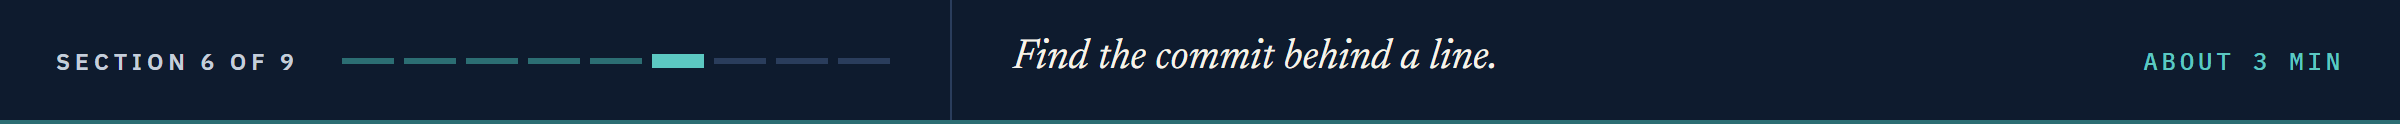

## 6.6 Which Notebook Wrote Each Line: `git blame`

### Read the Diff, Commit

In [31]:
# what changed, then the commit and the history, as in notebook 05
!git -C "{work}" diff --stat
subject = 'Notebook 06: change_bp, return_pct, and change_since_bp'
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "{subject}"
!git -C "{work}" log --oneline --decorate

 marketdata.py      | 53 +++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 51 +++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 104 insertions(+)
1f5838a (HEAD -> main) Notebook 06: change_bp, return_pct, and change_since_bp
ace289a (tag: week1) Notebook 05: write_cache, read_cache, and cached_fred_series
9f01b1c Notebook 04: last_per_period and value_as_of
a439502 Notebook 03: missing_weekdays, align, and stale_runs
ceea769 Notebook 02: fred_params, parse_fred_observations, and fred_series
a28686d Notebook 01: get_secret, a .gitignore, and .env.example


### Three Functions, Three Notebooks

Q. Which commit wrote the first line of `get_secret`, of `value_as_of`, and of `change_bp`?

In [32]:
# -L "/text/,+1" is the one line holding the text; -s drops the author and date;
# --root shows the first commit's hash like any other
lines = '-L "/def get_secret/,+1" -L "/def value_as_of/,+1" -L "/def change_bp/,+1"'
!git -C "{work}" blame -s --root {lines} marketdata.py

a28686d8  17) def get_secret(name: str, env_file: str | Path) -> str:
9f01b1c1 251) def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
1f5838a2 339) def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:


Each line starts with the hash of the commit that wrote it, then its line number: match them to the log.

### Predict 4: The Line Inside `change_bp`

**Predict 4**

Q. `_check_series` was written in notebook 04, and `change_bp` calls it. Which commit does `git blame` name for the line `_check_series(series, "series")` inside `change_bp`?

A) Notebook 04's
B) Today's
C) The first commit

### Blame the Whole Function

In [33]:
# from the def line to the line holding "return difference"
!git -C "{work}" blame -s -L "/def change_bp/,/return difference/" marketdata.py

1f5838a2 339) def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
1f5838a2 340)     """Change over `periods` observations, in basis points.
1f5838a2 341) 
1f5838a2 342)     Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
1f5838a2 343)     percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
1f5838a2 344)     Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
1f5838a2 345)     Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
1f5838a2 346)     Excel: =(B3-B2)*100 for a yield in percent.
1f5838a2 347)     Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
1f5838a2 348)     ascending dates.
1f5838a2 349)     """
1f5838a2 350)     _check_series(series, "series")
1f5838a2 351)     if periods < 1:
1f5838a2 352)         raise Value

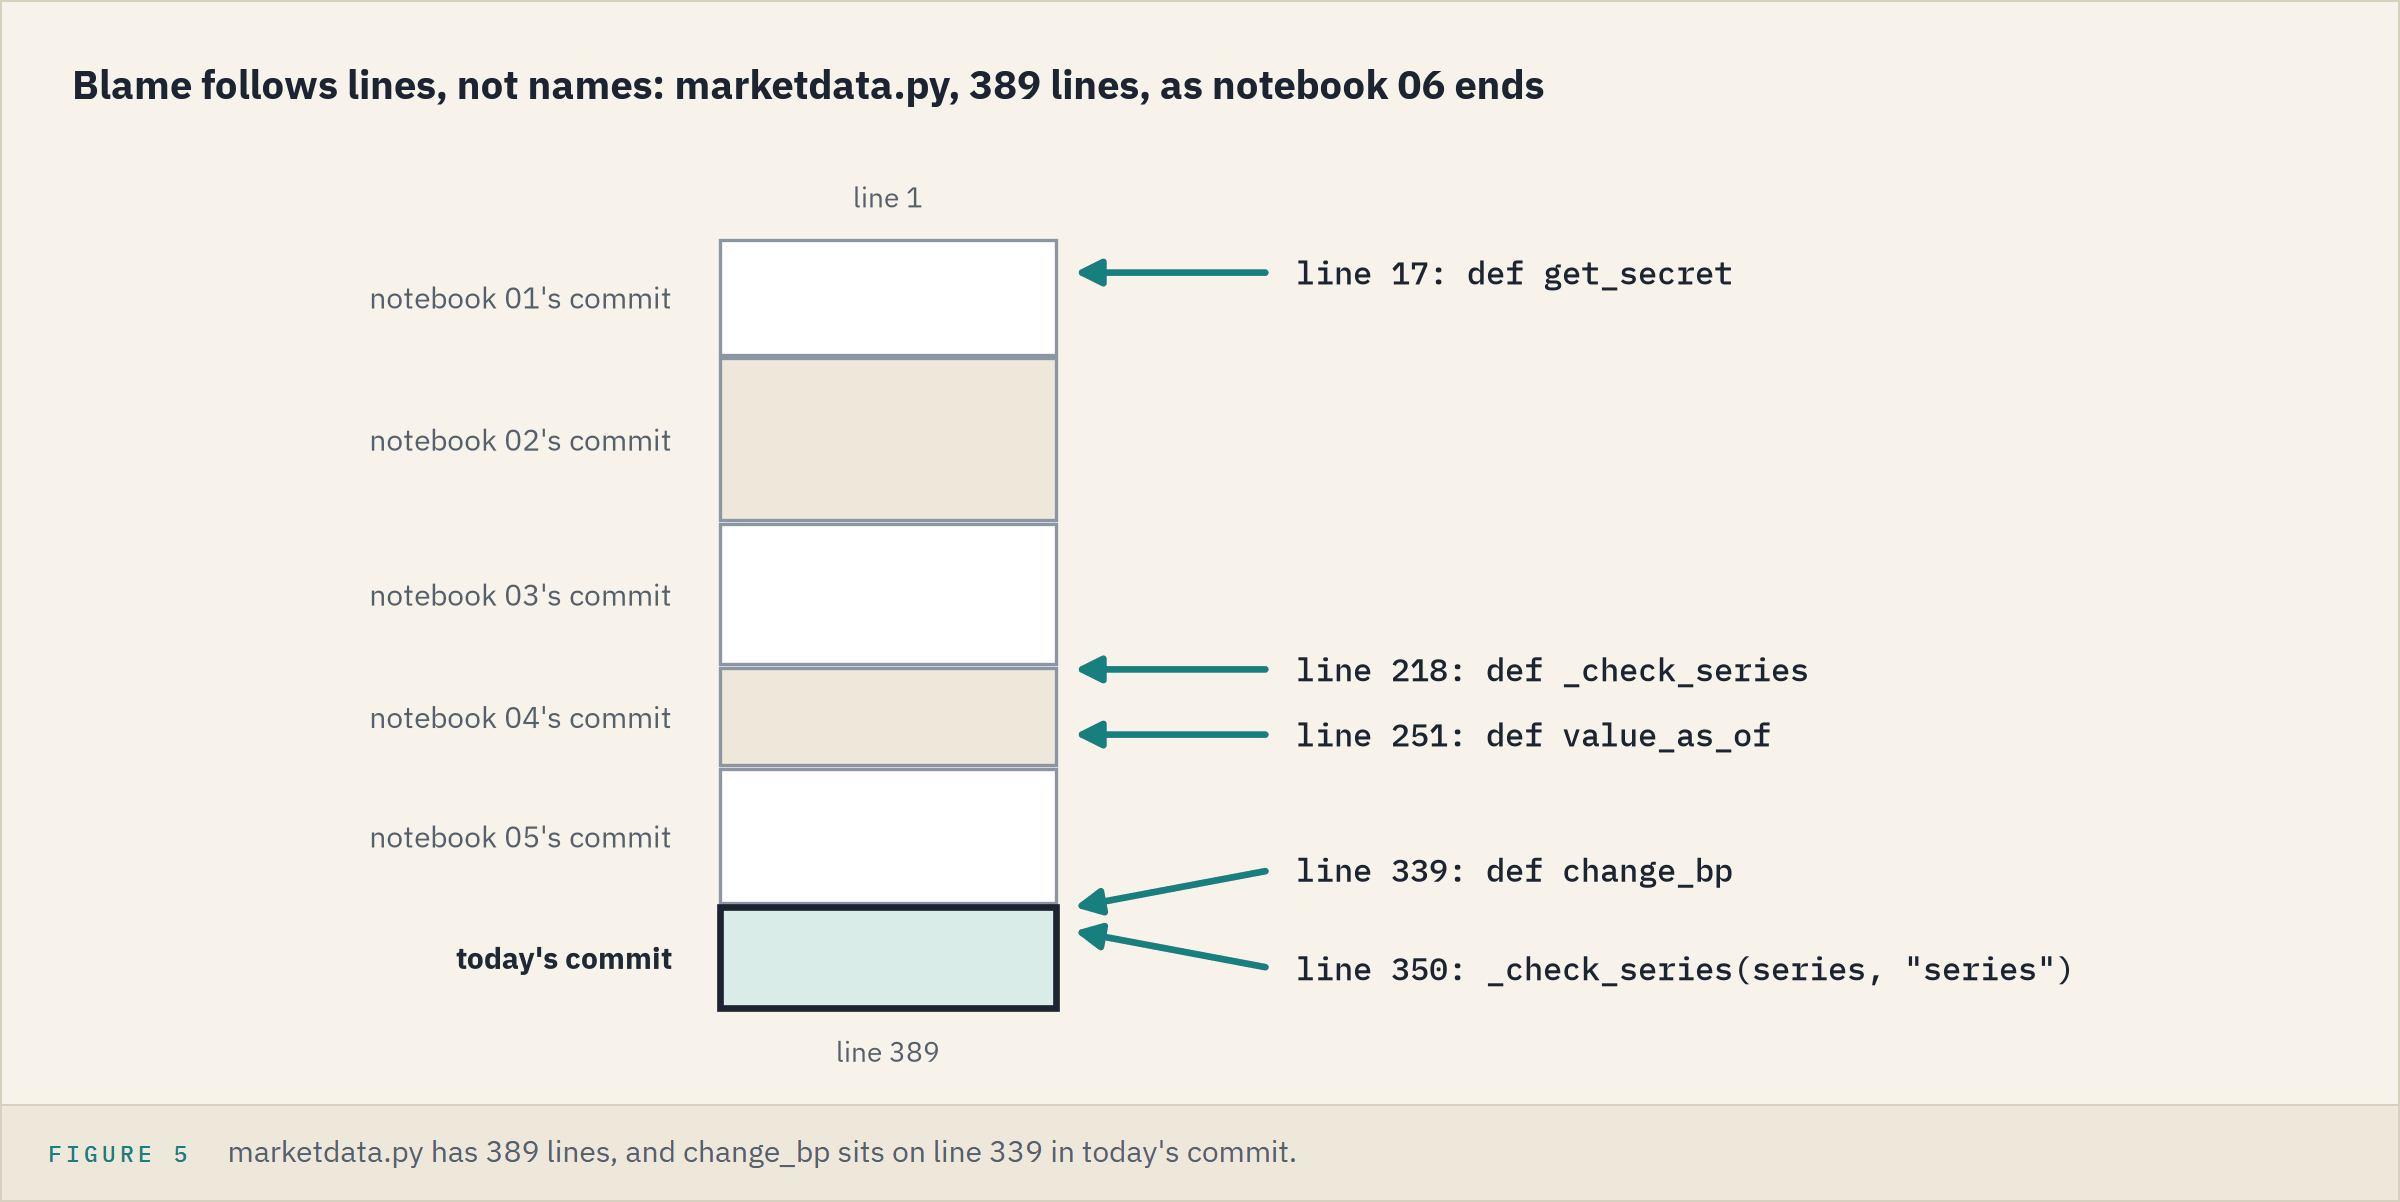

B: blame follows lines, not names.
`_check_series` was defined in notebook 04, but the line that calls it was written today.

**`git blame` names the commit behind each line, and so the reason for it. Now the bond the note asked about.**

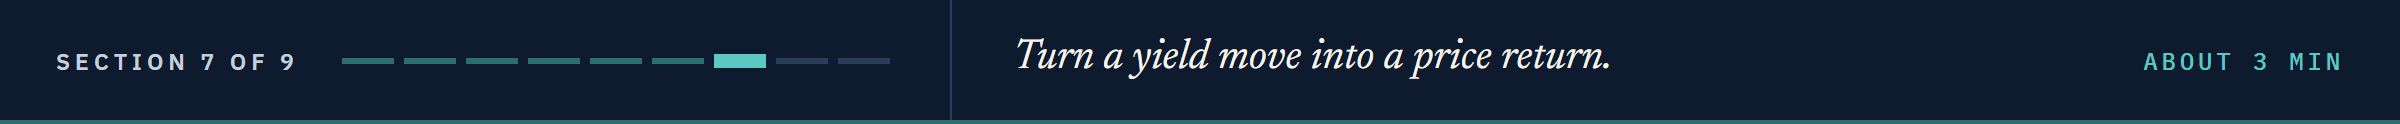

## 6.7 A Price Return From Your `bondmath`

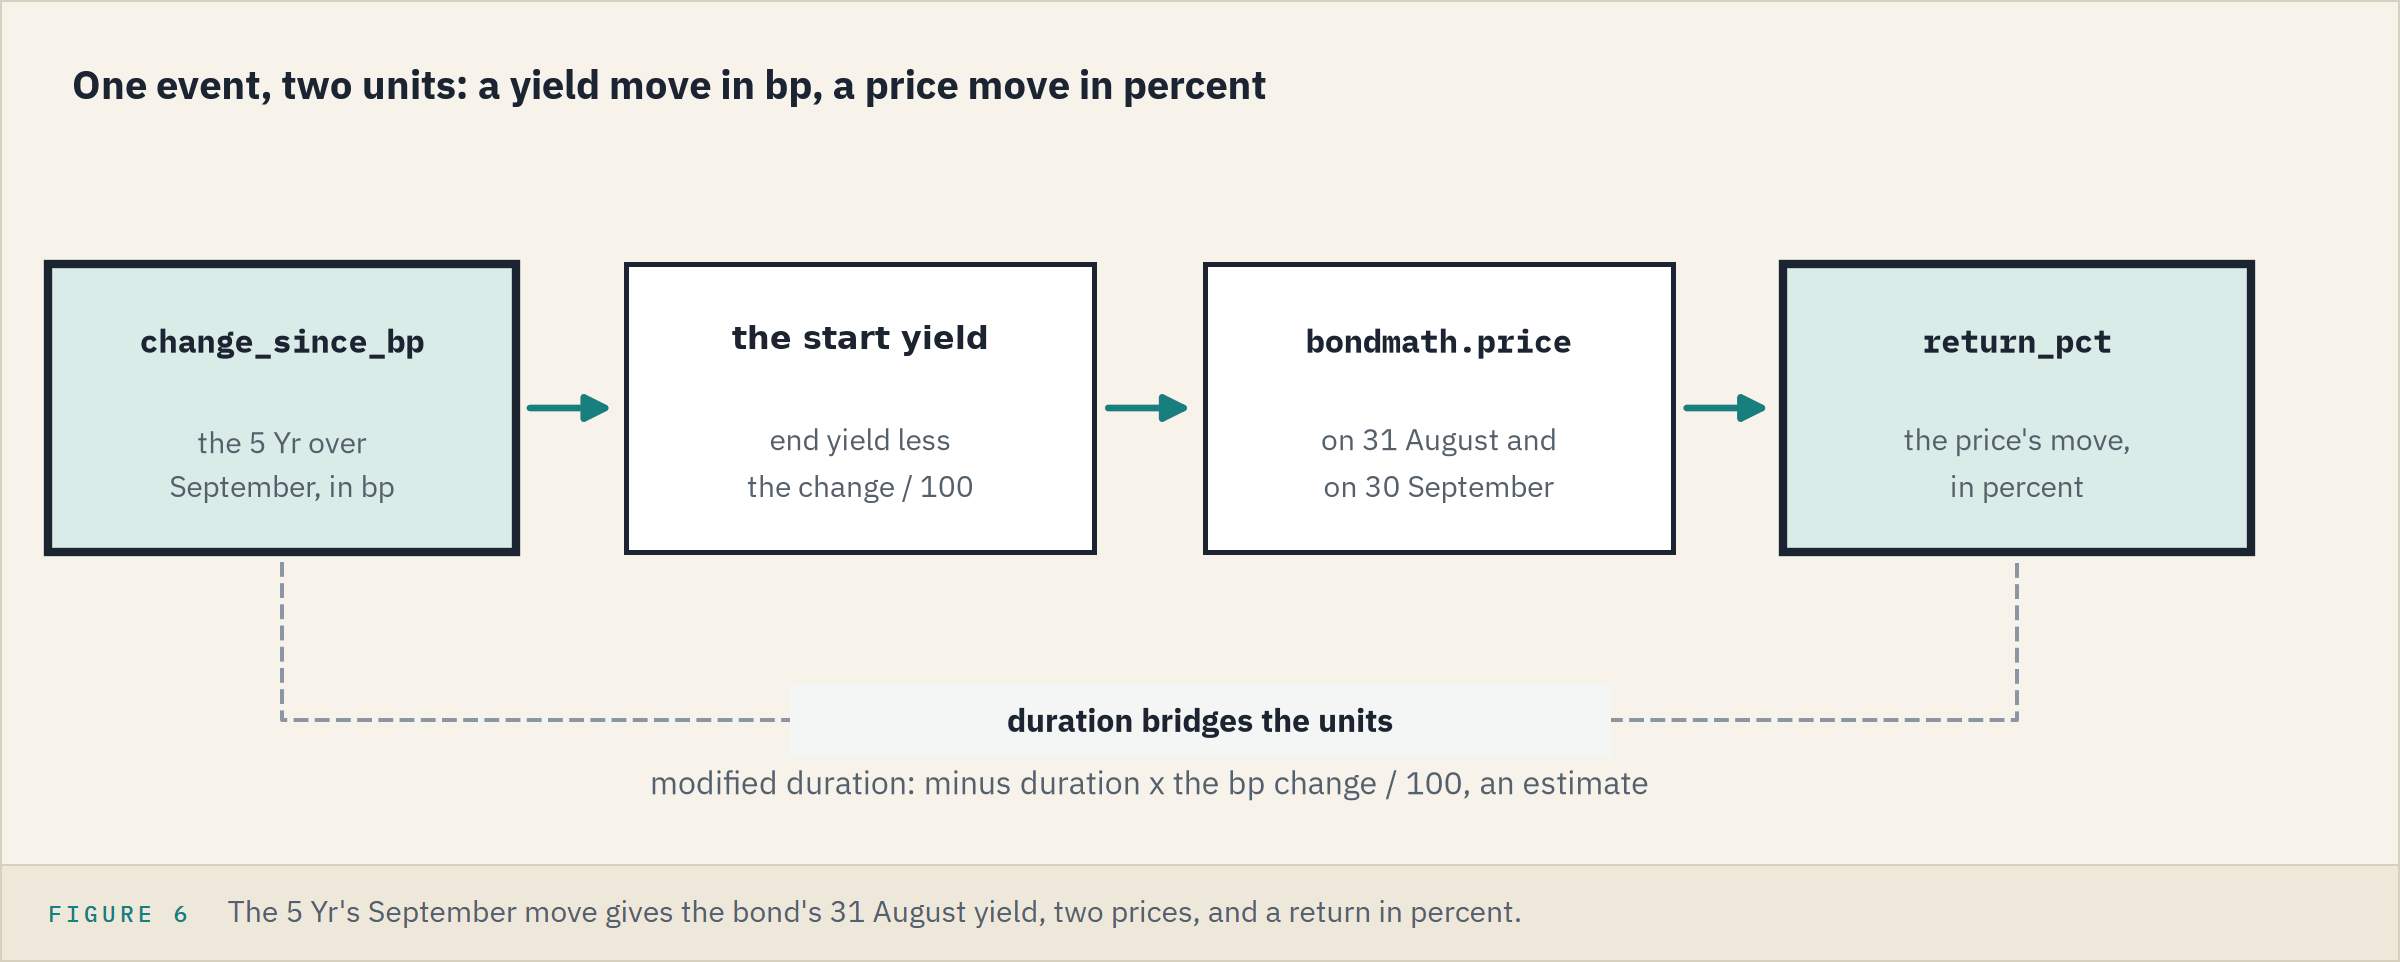

Quorvane Energy, Course 2's synthetic bond: a 5.25 percent coupon, maturing 2031-09-30, yielding 5.40 percent on 2026-09-30.
Take its yield to have moved over September by exactly the 5 Yr's change.

### September's Move in the 5 Yr

In [34]:
# Quorvane's coupon and maturity, and its yield on 2026-09-30, in percent
coupon_pct, maturity, yield_end_pct = 5.25, date(2031, 9, 30), 5.40
five_sept_bp = md.change_since_bp(treasury['5 Yr'], '2026-09-30', '2026-08-31')
# the yield on 31 August: bp back to percent is a divide by 100
yield_start_pct = yield_end_pct - five_sept_bp / 100
print(f'5 Yr over September: {five_sept_bp:+.0f} bp; the bond from {yield_start_pct:.2f} percent')

5 Yr over September: +60 bp; the bond from 4.80 percent


### Price It on Both Dates

In [35]:
# Course 2's price on each date, then today's return_pct on the pair
bond_prices = pd.Series([bondmath.price(date(2026, 8, 31), maturity, coupon_pct, yield_start_pct),
                         bondmath.price(date(2026, 9, 30), maturity, coupon_pct, yield_end_pct)],
                        index=pd.to_datetime(['2026-08-31', '2026-09-30']))
bond_return = md.return_pct(bond_prices).iloc[-1]
print(f'{bond_prices.iloc[0]:.6f} to {bond_prices.iloc[1]:.6f}: {bond_return:.4f} percent')

102.004270 to 99.350327: -2.6018 percent


A clean-price return: the coupon paid on 2026-09-30 and the accrued interest are left out.

**Excel side by side.** 4.800000000000001 in A1 and 5.4 in A2.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Price on 31 August, B1</td><td align="left"><code>bondmath.price(...)</code></td><td align="left"><code>=PRICE(DATE(2026,8,31),DATE(2031,9,30),5.25/100,A1/100,100,2,0)</code></td><td align="left">102.00426950087292</td></tr>
<tr><td align="left">Price on 30 September, B2</td><td align="left"><code>bondmath.price(...)</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2031,9,30),5.25/100,A2/100,100,2,0)</code></td><td align="left">99.35032727691544</td></tr>
<tr><td align="left">The return in percent</td><td align="left"><code>md.return_pct(bond_prices)</code></td><td align="left"><code>=(B2/B1-1)*100</code></td><td align="left">-2.601795235575677</td></tr>
</table>
<br clear="left">

### Duration Bridges the Units

In [36]:
# Course 2's modified duration on 31 August, then -duration x the move in percent
duration = bondmath.modified_duration(date(2026, 8, 31), maturity, coupon_pct, yield_start_pct)
estimate_pct = -duration * five_sept_bp / 100
print(f'Duration {duration:.4f}: estimate {estimate_pct:.4f} percent, repriced {bond_return:.4f}')

Duration 4.3355: estimate -2.6013 percent, repriced -2.6018


The two agree so closely because three small pieces nearly cancel.
Convexity adds about 0.04 percent, and a month less to maturity about 0.01.
Duration's percent is of the dirty price, and this return's of the clean price, which takes about 0.05 away.

**One event, two units: +60 bp on the yield, -2.60 percent on the price, and duration turns one into the other only because the move is in bp.**

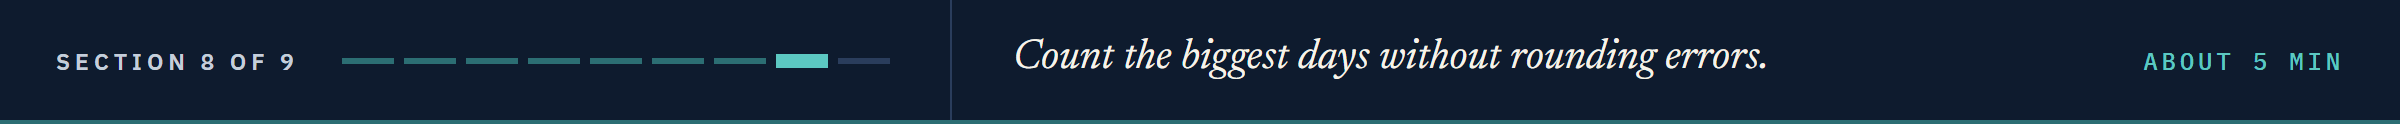

## 6.8 The Largest Daily Moves of 2026

The note's last ask.

### The Biggest Days

In [37]:
# 2026's daily changes, rounded to 6 decimals first: the next cell shows why
ten_2026 = md.change_bp(ten).loc['2026']
rounded = ten_2026.round(6)
# the five largest by size; keep='all' also keeps every day tied with the fifth
largest = rounded.abs().nlargest(5, keep='all')
rounded[largest.index]

date
2026-09-23    15.0
2026-03-20    14.0
2026-05-15    12.0
2026-09-10    12.0
2026-05-20   -10.0
2026-06-11   -10.0
Name: 10 Yr, dtype: float64

Six days: two tie at 10 bp, the fifth place.

**Excel side by side.** The daily changes in C251:C440.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The largest rise, and its date</td><td align="left"><code>ten_2026.max()</code>, <code>.idxmax()</code></td><td align="left"><code>=MAX(C251:C440)</code>, <code>=XLOOKUP(MAX(C251:C440),C251:C440,A251:A440)</code></td><td align="left">15.000000000000036 on 2026-09-23</td></tr>
<tr><td align="left">The largest fall, and its date</td><td align="left"><code>ten_2026.min()</code>, <code>.idxmin()</code></td><td align="left"><code>=MIN(C251:C440)</code>, the same <code>XLOOKUP</code></td><td align="left">-9.999999999999964 on 2026-05-20, the first of two</td></tr>
</table>
<br clear="left">

### Why Round First

In [38]:
# how many days moved 10 bp or more, either way, unrounded and rounded
print(f'Unrounded: {(ten_2026.abs() >= 10).sum()} days; '
      f'rounded: {(rounded.abs() >= 10).sum()} days')
print(ten_2026.loc[['2026-05-20', '2026-06-11']].tolist())

Unrounded: 4 days; rounded: 6 days
[-9.999999999999964, -9.999999999999964]


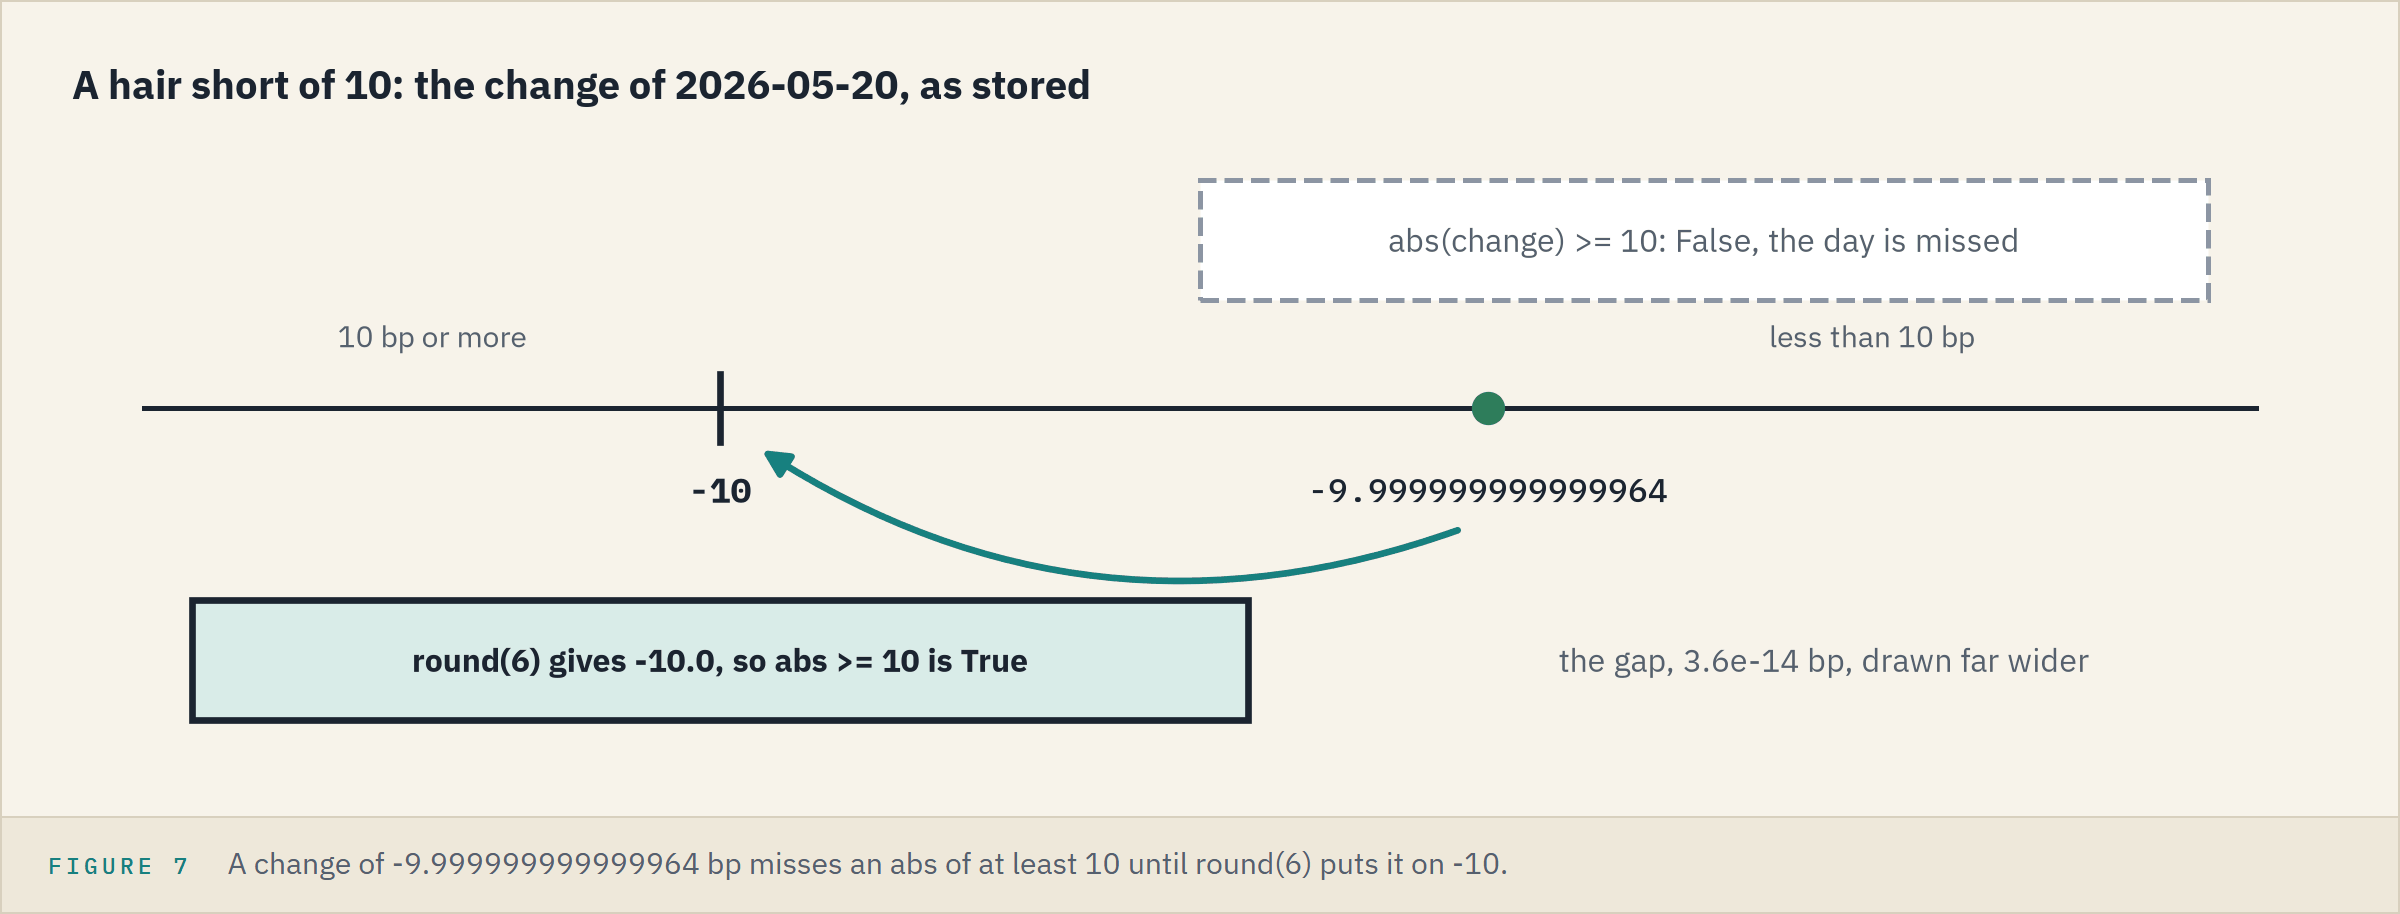

Both falls are stored a hair short of 10: the binary tail of Course 1's `0.1 + 0.2`.
Round to 6 decimals before a count, a threshold or a rank.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Days of 10 bp or more</td><td align="left"><code>(ten_2026.abs() &gt;= 10).sum()</code></td><td align="left"><code>=SUMPRODUCT(--(ABS(C251:C440)&gt;=10))</code></td><td align="left">4</td></tr>
<tr><td align="left">The same, rounded</td><td align="left"><code>(rounded.abs() &gt;= 10).sum()</code></td><td align="left"><code>=SUMPRODUCT(--(ROUND(ABS(C251:C440),6)&gt;=10))</code></td><td align="left">6</td></tr>
</table>
<br clear="left">

### Predict 5: At 5 bp

**Predict 5**

Q. At 10 bp the tail hid 2 days. At 5 bp, how many does it hide?

A) None: only large moves carry it
B) About 2
C) More than 10

### Count Again

In [39]:
# the same count at 5 bp
print(f'At 5 bp: {(ten_2026.abs() >= 5).sum()} days unrounded, '
      f'{(rounded.abs() >= 5).sum()} rounded')

At 5 bp: 42 days unrounded, 58 rounded


C: 16 days.
Moves land on whole bp, and more days sit exactly on 5 than on 10.

### The Year, Day by Day

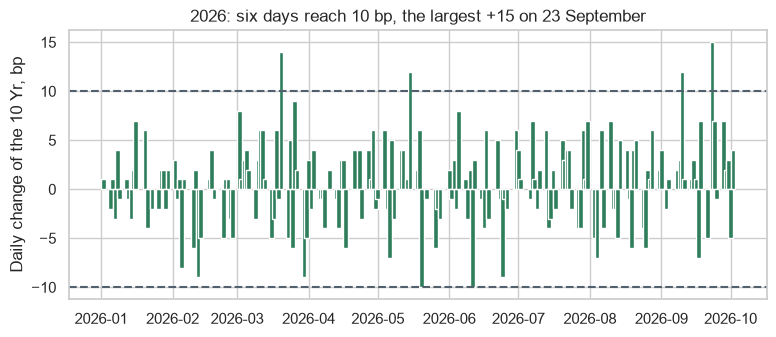

In [40]:
# every 2026 daily change, with dashed lines at plus and minus 10 bp
fig, ax = plt.subplots(figsize=(9, 3.5))
# width=2: each bar two days wide, so a year of bars stays visible
ax.bar(rounded.index, rounded.values, width=2)
ax.axhline(10, color='#52606D', linestyle='--')
ax.axhline(-10, color='#52606D', linestyle='--')
ax.set_title('2026: six days reach 10 bp, the largest +15 on 23 September')
ax.set_ylabel('Daily change of the 10 Yr, bp')
plt.show()

### How Often Each Size

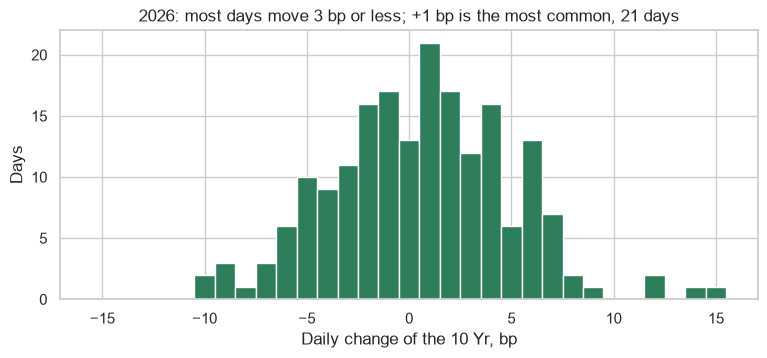

In [41]:
# one bar per whole bp: the bin edges sit halfway between whole numbers
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(rounded, bins=[edge + 0.5 for edge in range(-16, 16)], color='#2E7D5B')
ax.set_title('2026: most days move 3 bp or less; +1 bp is the most common, 21 days')
ax.set_xlabel('Daily change of the 10 Yr, bp')
ax.set_ylabel('Days')
plt.show()

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Days of +1 bp</td><td align="left"><code>((rounded &gt;= 0.5) &amp; (rounded &lt; 1.5)).sum()</code></td><td align="left"><code>=COUNTIFS(C251:C440,"&gt;=0.5",C251:C440,"&lt;1.5")</code></td><td align="left">21</td></tr>
</table>
<br clear="left">

**2026's biggest 10 Yr day was +15 bp on 23 September. A count or a rank of computed changes rounds the binary tail off first. The note is answered.**

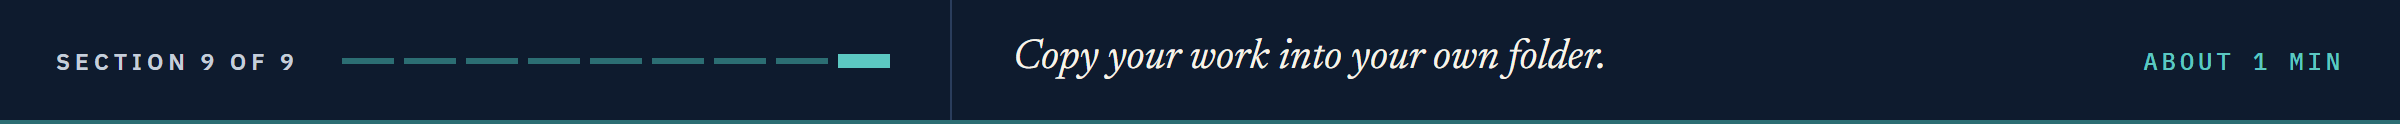

## Bring It Home

Copy the two files and Excel's reference rows into your own folder, test, and commit.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_06_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py", "$work\course3_excel_reference.csv" .
python -m pytest -q test_marketdata.py
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Notebook 06: change_bp, return_pct, and change_since_bp"
git blame -L "/def change_bp/,+1" marketdata.py
```

The copy replaces your two files, so anything of your own goes into the work folder first.
pytest shows 25 passed, and `git blame` names your new commit for the first line of `change_bp`.
The reference file stays out of Git.
In Colab, download the three files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Say why yields and spreads change in bp and prices in percent.
* Measure a change k rows back with `change_bp`, for a yield in percent or a spread in bp.
* Explain why a percent change of a yield misleads.
* Measure a change since a date with `change_since_bp`, from as-of values at both ends.
* Price a bond on two dates with `bondmath` and put its return beside the yield change.
* Round before a count or a rank of computed changes.
* Find the commit behind a line with `git blame -L`.

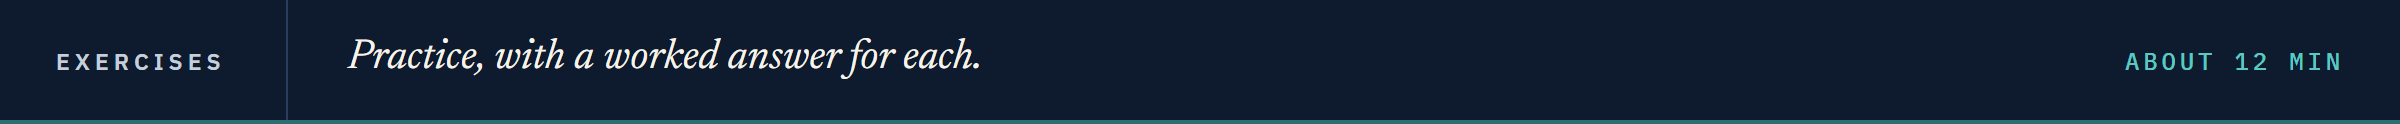

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Every exercise uses `treasury`, `spreads` and `reference` from above, and needs no key.
Replace each `...` with your code, then run the cell.
Run the next cell first.

In [42]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. Weekly changes in the 2 Yr: take each week's last row with `md.last_per_period(..., 'W-FRI')`, then `md.change_bp`. Keep the weeks ending in September 2026. Store how many there are in **ex1_count** and the largest weekly change, in bp, in **ex1_largest**.

In [43]:
ex1_count = ...
ex1_largest = ...
check('Exercise 1 the number of weeks', ex1_count, 4)
check('Exercise 1 the largest weekly change', ex1_largest, 25.99999999999998)

Exercise 1 the number of weeks: not attempted yet
Exercise 1 the largest weekly change: not attempted yet


### Exercise 2

Q. Month to date, as of 2026-10-02: the change in each synthetic spread since the last day of September, `pd.Timestamp('2026-10-01') - pd.Timedelta(days=1)`. The spreads are in bp. Store the investment grade change in **ex2_ig** and the high yield change in **ex2_hy**.

In [44]:
ex2_ig = ...
ex2_hy = ...
check('Exercise 2 investment grade, month to date', ex2_ig, -1.7999999999999972)
check('Exercise 2 high yield, month to date', ex2_hy, -6.0)

Exercise 2 investment grade, month to date: not attempted yet
Exercise 2 high yield, month to date: not attempted yet


### Exercise 3

Q. Add `yield_change_table(curve, tenors, as_of)` to your module, docstring first: one row per tenor, columns `level_pct` (the as-of value), `chg_1d_bp` (from the row before the as-of row), `chg_1w_bp` and `chg_1m_bp`, each tenor's blank rows dropped first. Inside the module, call `value_as_of` and `change_since_bp` without `md.`. Add `test_yield_change_table_known_date`: the 2 Yr and 10 Yr on 2026-10-02, the 10 Yr level 5.28, the 1-day change against `md.change_bp`, the 1-month change against `read_reference()`. Run pytest, reload, build the table for the 2, 5, 10 and 30 Yr on 2026-10-02, and store the 30 Yr's `chg_1m_bp` in **ex3_value**.

In [45]:
%%writefile -a marketdata.py


# Exercise 3: write yield_change_table(curve, tenors, as_of) below this line

Appending to marketdata.py


In [46]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_yield_change_table_known_date() below this line

Appending to test_marketdata.py


In [47]:
# run pytest, reload the module, then store the answer
ex3_value = ...
check('Exercise 3 the 30 Yr one-month change', ex3_value, 36.00000000000003)

Exercise 3 the 30 Yr one-month change: not attempted yet


### Exercise 4: AI check

You gave an AI assistant the docstring below as the request: the docstring is the prompt.
This came back, written for this course in the style of an assistant's answer.

In [48]:
# written for this course in the style of an AI assistant's answer.
# It runs, and it contains one bug.
def daily_change_bp(series):
    """Daily change of a yield series, in basis points.

    Units: yields in percent in, bp out: (y_t - y_{t-1}) x 100, from the previous
    observation (row), whatever the calendar gap. The first value is NaN.
    Never a percent change of the yield level.
    """
    # pandas' built-in change from the previous row, times 100 so it reads in basis points
    return series.pct_change() * 100

Q. The 10 Yr rose from 5.24 to 5.28 percent on 2026-10-02. What does the function return for that day?

In [49]:
# the assistant's function on the 10 Yr: its last day
print(f"{daily_change_bp(treasury['10 Yr']).iloc[-1]:.4f}")

0.7634


Q. Test it against Excel's daily change before you trust it.

In [50]:
# Excel's =(B3-B2)*100 on the 190 rows of 2026
ai_changes = daily_change_bp(treasury['10 Yr']).loc[reference.index]
ai_gap = (ai_changes - reference['chg_10y_bp']).abs().max()
assert ai_gap <= 1e-9, f"differs from Excel's daily change in bp by up to {ai_gap:.2f} bp"
print(f'Equal to Excel on all {len(reference)} rows of 2026: largest gap {ai_gap:.1e} bp')

AssertionError: differs from Excel's daily change in bp by up to 11.98 bp

Q. Fix the function, run it and the test again, then store its change for the last day in **ex4_last**.

In [51]:
ex4_last = ...
check('Exercise 4 the last daily change', ex4_last, 4.0000000000000036)

Exercise 4 the last daily change: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">On the day, week, month and year</td><td align="left">10 Yr +4, +11, +49 and +110 bp as of 2026-10-02, with the 2, 5 and 30 Yr and both spreads beside it</td></tr>
<tr><td align="left">Each in its right unit, tied to Excel</td><td align="left">bp for yields and spreads, percent for prices; 190 of 190 rows equal</td></tr>
<tr><td align="left">A holiday never a zero move</td><td align="left">Tuesday 8 September is a change from Friday 4 September</td></tr>
<tr><td align="left">September's 5 Yr move on a bond</td><td align="left">+60 bp, and Quorvane's clean price -2.60 percent</td></tr>
<tr><td align="left">The biggest days of 2026</td><td align="left">+15 bp on 2026-09-23; -10 bp on 2026-05-20 and 2026-06-11</td></tr>
</table>
<br clear="left">

Be proud: two mistakes that raise no error, a wrong unit and a hidden binary tail, are now caught in code.

Next, Rolling Windows and Volatility (notebook 07) turns today's daily changes into a measure of how much a series has been moving.

[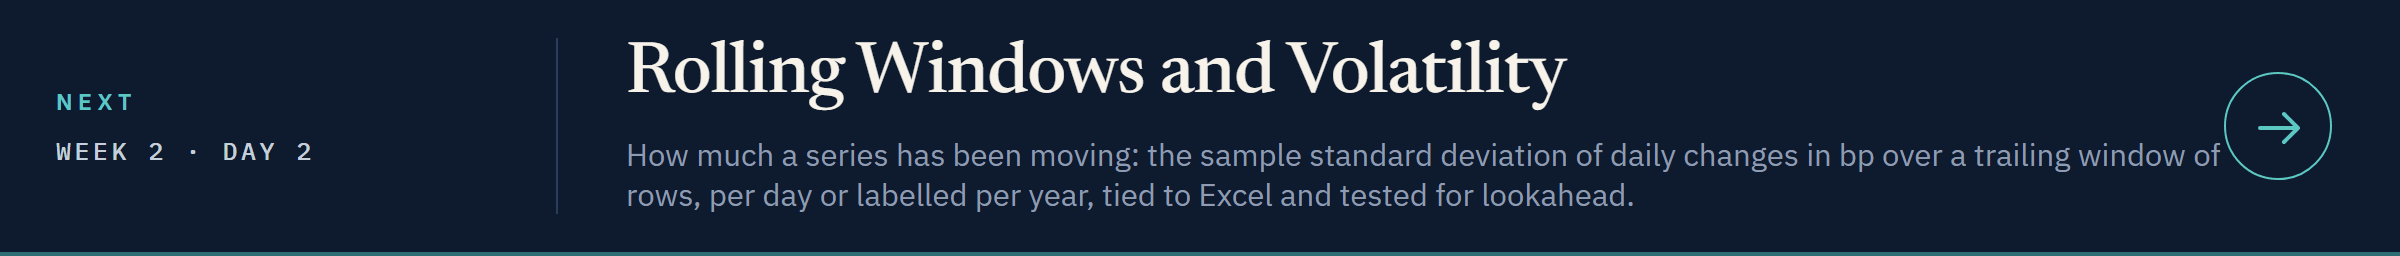](../day2/07_rolling_windows_and_volatility.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day2/07_rolling_windows_and_volatility.ipynb)